In [ ]:
try:
    import chembl_webresource_client
    import transformers
    import joblib
except ImportError:
    print("⬇️ Installing Dependencies (chembl_webresource_client, transformers, accelerate, joblib)...")
    import subprocess
    subprocess.check_call(["pip", "install", "chembl_webresource_client", "transformers", "accelerate", "datasets", "joblib", "scikit-learn"])
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoModel, AutoTokenizer
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from chembl_webresource_client.new_client import new_client
from tqdm.auto import tqdm
import pandas as pd
import numpy as np
import os
import joblib
import shutil
# --- 1. CONFIG ---
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MOLFORMER_NAME = "ibm/MoLFormer-XL-both-10pct"
CBERTA_NAME = "seyonec/ChemBERTa-zinc-base-v1"
BATCH_SIZE = 16
EPOCHS = 4
LR = 2e-5
# 🆕 FRESH START CONFIG (Cell 1 Standard)
RESUME_TRAINING = False
ADD_RF_ONLY = False # Full Training Mode
print(f">>> 🚀 Tier 3 ENSEMBLE Training Initiated on {DEVICE}")
# --- HELPER: MOUNT DRIVE ---
def mount_drive():
    if not os.path.exists("/content/drive"):
        try:
            from google.colab import drive
            print("    📂 Mounting Google Drive for Data Access...")
            drive.mount('/content/drive')
        except:
            pass
# --- 2. DATA (Enhanced for Drive Reuse) ---
def get_data():
    mount_drive()
    final_csv = "chembl_alzheimers.csv"
    # 0. Check for Final File (Enhanced Search)
    # Checks: Local, Drive Root, BioDockify Folder, Colab Notebooks
    paths = [
        final_csv,
        f"/content/drive/MyDrive/{final_csv}",
        f"/content/drive/MyDrive/BioDockify/{final_csv}",
        f"/content/drive/MyDrive/Colab Notebooks/{final_csv}"
    ]

    print("    🔍 Checking for existing data in Drive...")
    for p in paths:
        if os.path.exists(p):
            print(f"    ✅ Found Data: {p} (Skipping Download!)")
            return pd.read_csv(p)

    # 1. Setup Checkpointing
    print(">>> ⬇️ Starting Resumable Download (Data not found in Drive)...")
    targets = [
        {'id': 'CHEMBL220', 'name': 'AChE'},
        {'id': 'CHEMBL340', 'name': 'BACE1'},
        {'id': 'CHEMBL262', 'name': 'GSK3b'}
    ]
    activity = new_client.activity
    # Define save folder
    save_dir = "."
    if os.path.isdir("/content/drive/MyDrive"):
        save_dir = "/content/drive/MyDrive/BioDockify_Checkpoints"
        os.makedirs(save_dir, exist_ok=True)
        print(f"    📂 Saving checkpoints to: {save_dir}")
    combined_frames = []
    for t in targets:
        checkpoint_file = os.path.join(save_dir, f"checkpoint_{t['name']}.csv")
        if os.path.exists(checkpoint_file):
            print(f"    ✅ Found Checkpoint for {t['name']}, skipping download.")
            combined_frames.append(pd.read_csv(checkpoint_file))
        else:
            print(f"    📥 Downloading {t['name']} ({t['id']})...")
            try:
                # Use exact logic user provided
                res = activity.filter(target_chembl_id=t['id'], pchembl_value__isnull=False).only('canonical_smiles', 'pchembl_value')
                data = []
                for act in tqdm(res, desc=t['name']):
                    if act.get('canonical_smiles'):
                        data.append({'smiles': act['canonical_smiles'], 'pIC50': float(act['pchembl_value'])})
                df_t = pd.DataFrame(data)
                df_t.to_csv(checkpoint_file, index=False)
                combined_frames.append(df_t)
                print(f"    💾 Saved Checkpoint {t['name']} ({len(df_t)} rows)")
            except Exception as e:
                print(f"    ❌ Failed to download {t['name']}: {e}")
                print("    ⚠️ Try running again to resume!")
                raise e
    print("    🔄 Merging Checkpoints...")
    full_df = pd.concat(combined_frames, ignore_index=True)
    full_df = full_df.drop_duplicates(subset=['smiles'])
    full_df.to_csv(final_csv, index=False)
    if os.path.isdir("/content/drive/MyDrive"):
         full_df.to_csv(f"/content/drive/MyDrive/{final_csv}", index=False)
         print(f"    ✅ Saved Final Dataset to Drive: /content/drive/MyDrive/{final_csv}")
    return full_df
# --- 3. THE ENSEMBLE ARCHITECTURE (Stacked) ---
class BiModalEnsemble(nn.Module):
    def __init__(self):
        super().__init__()
        # Stream 1: MolFormer
        self.mol_enc = AutoModel.from_pretrained(MOLFORMER_NAME, trust_remote_code=True)
        # Stream 2: ChemBERTa
        self.cberta_enc = AutoModel.from_pretrained(CBERTA_NAME)
        # Fusion Head
        self.classifier = nn.Sequential(
            nn.Linear(768 + 768, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )
    def forward(self, mf_ids, mf_mask, cb_ids, cb_mask):
        mf_out = self.mol_enc(mf_ids, mf_mask).pooler_output
        cb_out = self.cberta_enc(cb_ids, cb_mask).pooler_output
        combined = torch.cat((mf_out, cb_out), dim=1)
        return self.classifier(combined)
    def get_molformer_embeddings(self, mf_ids, mf_mask):
        with torch.no_grad():
            return self.mol_enc(mf_ids, mf_mask).pooler_output.cpu().numpy()
# --- 4. EXECUTION LOOP ---
def tokenize_batch(smiles_list, tokenizer, max_len=128):
    return tokenizer(
        smiles_list, padding=True, truncation=True,
        max_length=max_len, return_tensors="pt"
    )
def main():
    df = get_data()
    y_all = np.array((df['pIC50'] >= 7.0).astype(int).tolist())
    X_all = np.array(df['smiles'].tolist())
    n_pos = sum(y_all)
    pos_weight = (len(y_all) - n_pos) / n_pos if n_pos > 0 else 1.0
    print(f"    📊 Class Balance: Actives={n_pos} (Weight={pos_weight:.2f})")
    mf_tok = AutoTokenizer.from_pretrained(MOLFORMER_NAME, trust_remote_code=True)
    cb_tok = AutoTokenizer.from_pretrained(CBERTA_NAME)
    model = BiModalEnsemble().to(DEVICE)

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    for fold, (tr_idx, val_idx) in enumerate(skf.split(X_all, y_all)):
        print(f"\n🔄 ENSEMBLE FOLD {fold+1}/5 STARTED...")

        X_tr, X_val = X_all[tr_idx], X_all[val_idx]
        y_tr, y_val = y_all[tr_idx], y_all[val_idx]
        # 1. Deep Training
        optim = torch.optim.AdamW(model.parameters(), lr=LR)
        crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight]).to(DEVICE))
        model.train()
        # Actual Training Loop
        for epoch in range(EPOCHS):
            batch_losses = []
            perm = np.random.permutation(len(X_tr))
            X_tr_s, y_tr_s = X_tr[perm], y_tr[perm]

            pbar = tqdm(range(0, len(X_tr_s), BATCH_SIZE), desc=f"Ep {epoch+1}", leave=False)
            for i in pbar:
                batch_smiles = X_tr_s[i:i+BATCH_SIZE].tolist()
                batch_y = torch.tensor(y_tr_s[i:i+BATCH_SIZE], dtype=torch.float32).unsqueeze(1).to(DEVICE)

                mf_in = tokenize_batch(batch_smiles, mf_tok).to(DEVICE)
                cb_in = tokenize_batch(batch_smiles, cb_tok).to(DEVICE)

                optim.zero_grad()
                logits = model(mf_in['input_ids'], mf_in['attention_mask'],
                             cb_in['input_ids'], cb_in['attention_mask'])
                loss = crit(logits, batch_y)
                loss.backward()
                optim.step()
                batch_losses.append(loss.item())
            print(f"    Epoch {epoch+1} Loss: {np.mean(batch_losses):.4f}")
        # 2. Random Forest Training
        print("    [2/3] Extracting Embeddings & Training Random Forest...")
        model.eval()
        def get_embeds(arr):
            out = []
            for i in range(0, len(arr), 32):
                batch = arr[i:i+32].tolist()
                mf_in = tokenize_batch(batch, mf_tok).to(DEVICE)
                out.append(model.get_molformer_embeddings(mf_in['input_ids'], mf_in['attention_mask']))
            return np.vstack(out)

        X_tr_emb = get_embeds(X_tr)
        X_val_emb = get_embeds(X_val)

        rf_model = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
        rf_model.fit(X_tr_emb, y_tr)
        # 3. Meta-Learner Stacking
        print("    [3/3] Meta-Learner Stacking...")
        val_logits = []
        with torch.no_grad():
            for i in range(0, len(X_val), 32):
                batch = X_val[i:i+32].tolist()
                mf_in = tokenize_batch(batch, mf_tok).to(DEVICE)
                cb_in = tokenize_batch(batch, cb_tok).to(DEVICE)
                val_logits.append(model(mf_in['input_ids'], mf_in['attention_mask'],
                                      cb_in['input_ids'], cb_in['attention_mask']).cpu())
        probs_deep = torch.sigmoid(torch.cat(val_logits)).numpy().flatten()
        probs_rf = rf_model.predict_proba(X_val_emb)[:, 1]

        X_meta = np.vstack([probs_deep, probs_rf]).T
        meta_learner = LogisticRegression()
        meta_learner.fit(X_meta, y_val)

        acc = accuracy_score(y_val, meta_learner.predict(X_meta))
        print(f"    🌟 FOLD {fold+1} STACKED ACCURACY: {acc:.4%}")
        # Save Artifacts Locally
        p_name = f"biodockify_ensemble_fold{fold+1}.pth"
        rf_name = f"biodockify_rf_fold{fold+1}.joblib"
        meta_name = f"biodockify_meta_fold{fold+1}.joblib"

        torch.save(model.state_dict(), p_name)
        joblib.dump(rf_model, rf_name)
        joblib.dump(meta_learner, meta_name)
        print(f"    ✅ Model Saved Locally: {p_name}")
        # 🔄 AUTOMATIC DRIVE BACKUP
        if os.path.exists("/content/drive/MyDrive"):
            drive_folder = "/content/drive/MyDrive/BioDockify_Models"
            os.makedirs(drive_folder, exist_ok=True)
            print(f"    🔄 Backing up to Drive: {drive_folder}...")
            try:
                shutil.copy(p_name, os.path.join(drive_folder, p_name))
                shutil.copy(rf_name, os.path.join(drive_folder, rf_name))
                shutil.copy(meta_name, os.path.join(drive_folder, meta_name))
                print("    ✅ BACKUP SUCCESS! (Files are safe in Drive)")
            except Exception as e:
                print(f"    ⚠️ Backup Failed: {e}")
        break # Demo 1 fold
    print("\n🏆 ENSEMBLE TRAINING SCRIPT GENERATED.")
    print("👉 Implementation Details:")
    print("   1. Deep Fusion Model (Trained)")
    print("   2. Random Forest (Trained on Embeddings)")
    print("   3. Stacked Meta-Learner (Optimized)")
if __name__ == "__main__":
    main()

>>> 🚀 Tier 3 ENSEMBLE Training Initiated on cuda
    📂 Mounting Google Drive for Data Access...
Mounted at /content/drive
    🔍 Checking for existing data in Drive...
>>> ⬇️ Starting Resumable Download (Data not found in Drive)...
    📂 Saving checkpoints to: /content/drive/MyDrive/BioDockify_Checkpoints
    📥 Downloading AChE (CHEMBL220)...


AChE:   0%|          | 0/7941 [00:00<?, ?it/s]

    💾 Saved Checkpoint AChE (7940 rows)
    📥 Downloading BACE1 (CHEMBL340)...


BACE1:   0%|          | 0/29257 [00:00<?, ?it/s]

    💾 Saved Checkpoint BACE1 (29151 rows)
    📥 Downloading GSK3b (CHEMBL262)...


...

    Epoch 2 Loss: 0.5961


Ep 3:   0%|          | 0/1380 [00:00<?, ?it/s]

    Epoch 3 Loss: 0.4749


Ep 4:   0%|          | 0/1380 [00:00<?, ?it/s]

    Epoch 4 Loss: 0.3987
    [2/3] Extracting Embeddings & Training Random Forest...
    [3/3] Meta-Learner Stacking...
    🌟 FOLD 1 STACKED ACCURACY: 91.7391%
    ✅ Model Saved Locally: biodockify_ensemble_fold1.pth
    🔄 Backing up to Drive: /content/drive/MyDrive/BioDockify_Models...
    ✅ BACKUP SUCCESS! (Files are safe in Drive)

🏆 ENSEMBLE TRAINING SCRIPT GENERATED.
👉 Implementation Details:
   1. Deep Fusion Model (Trained)
   2. Random Forest (Trained on Embeddings)
   3. Stacked Meta-Learner (Optimized)


In [ ]:
CUSTOM_DRIVE_FOLDER = "/content/drive/MyDrive/BioDockify"
import subprocess
import sys
import os
import shutil
# --- 2. SETUP & INSTALL ---
packages = ['pandas', 'pubchempy', 'chembl_webresource_client', 'rdkit']
for pkg in packages:
    try:
        __import__(pkg.replace('-', '_'))
    except ImportError:
        print(f"⬇️ Installing {pkg}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])
import pandas as pd
from chembl_webresource_client.new_client import new_client
import pubchempy as pcp
from tqdm.auto import tqdm
import time
# --- 3. MOUNT DRIVE ---
try:
    from google.colab import drive
    if not os.path.isdir("/content/drive"):
        drive.mount('/content/drive')
except: pass
FINAL_FILENAME = "biodockify_global_plant_database.csv"
# --- 4. FETCHING LOGIC ---
def fetch_chembl():
    print("\n>>> 🧪 Fetching ChEMBL (Alzheimer's Compounds)...")
    try:
        activity = new_client.activity
        # AChE, BACE1, GSK3b
        targets = ["CHEMBL220", "CHEMBL3927", "CHEMBL262"]
        all_data = []
        for tid in targets:
            print(f"    Fetching {tid}...")
            res = activity.filter(target_chembl_id=tid, pchembl_value__gte=6).only('canonical_smiles')
            for r in tqdm(res[:2000], desc=tid): # Limit for speed
                 if r.get('canonical_smiles'):
                     all_data.append({'smiles': r['canonical_smiles'], 'source': 'ChEMBL'})
        return pd.DataFrame(all_data)
    except Exception as e:
        print(f"    ⚠️ ChEMBL Error: {e}")
        return pd.DataFrame()
def fetch_pubchem():
    print("\n>>> 🧬 Fetching PubChem (Neuroprotective)...")
    compounds = [
        'quercetin', 'curcumin', 'resveratrol', 'EGCG', 'galantamine',
        'huperzine A', 'luteolin', 'baicalein', 'rosmarinic acid', 'berberine'
    ]
    all_data = []
    for name in tqdm(compounds, desc="PubChem"):
        try:
            c = pcp.get_compounds(name, 'name')
            if c and c[0].canonical_smiles:
                all_data.append({'smiles': c[0].canonical_smiles, 'source': 'PubChem'})
            time.sleep(0.2)
        except: pass
    return pd.DataFrame(all_data)
def create_manual_db():
    print("\n>>> 🌱 Adding Manual Plant Database...")
    # Add your specific plant compounds here
    data = [
        ('Evolvulus alsinoides', 'CN1CCC2=CC(=C(C=C2C1)O)O'), # Shankhpushpi
        ('Curcuma longa', 'COC1=C(O)C=CC(=C1)C=CC(=O)CC(=O)C=CC2=CC(=C(O)C=C2)OC'), # Curcumin
        ('Bacopa monnieri', 'CC1CCC2(C)C(CC(O)C3C2CCC4(C)C3CCC5(C)C4CC(O)C5O)C1') # Bacoside A
    ]
    return pd.DataFrame(data, columns=['Plant', 'smiles']).assign(source='Manual')
# --- 5. MAIN ---
def main():
    # A. Check Paths
    paths = [
        os.path.join(CUSTOM_DRIVE_FOLDER, FINAL_FILENAME),
        f"/content/drive/MyDrive/{FINAL_FILENAME}"
    ]

    for p in paths:
        if os.path.exists(p):
            print(f"✅ FOUND EXISTING DATABASE IN DRIVE: {p}")
            print("   Copying to workspace...")
            shutil.copy(p, FINAL_FILENAME)
            print("   🚀 READY! You can skip to Screening (Cell 11).")
            return
    # B. Generate if not found
    print("⚠️ Database not found in Drive. Generating Fresh...")

    df1 = fetch_chembl()
    df2 = fetch_pubchem()
    df3 = create_manual_db()

    combined = pd.concat([df1, df2, df3], ignore_index=True)

    # Clean
    combined = combined.drop_duplicates(subset=['smiles']).dropna(subset=['smiles'])

    # Save Local
    combined.to_csv(FINAL_FILENAME, index=False)
    print(f"\n✅ Created {FINAL_FILENAME} with {len(combined)} compounds.")

    # Save to Custom Path
    if os.path.isdir(CUSTOM_DRIVE_FOLDER):
        dest = os.path.join(CUSTOM_DRIVE_FOLDER, FINAL_FILENAME)
        shutil.copy(FINAL_FILENAME, dest)
        print(f"💾 BACKED UP TO YOUR FOLDER: {dest}")
    elif os.path.isdir("/content/drive/MyDrive"):
        dest = f"/content/drive/MyDrive/{FINAL_FILENAME}"
        shutil.copy(FINAL_FILENAME, dest)
        print(f"💾 BACKED UP TO DRIVE: {dest}")
    else:
        print("⚠️ Drive not mounted. File saved locally only.")
if __name__ == "__main__":
    main()

✅ FOUND EXISTING DATABASE IN DRIVE: /content/drive/MyDrive/biodockify_global_plant_database.csv
   Copying to workspace...
   🚀 READY! You can skip to Screening (Cell 11).


In [ ]:
CUSTOM_DRIVE_FOLDER = "/content/drive/MyDrive/BioDockify"
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from transformers import AutoModel, AutoTokenizer
from tqdm.auto import tqdm
import joblib
import os
import shutil
# --- 2. CONFIG ---
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MOLFORMER_NAME = "ibm/MoLFormer-XL-both-10pct"
CBERTA_NAME = "seyonec/ChemBERTa-zinc-base-v1"
MODEL_FILE = "biodockify_ensemble_fold1.pth"
RF_FILE = "biodockify_rf_fold1.joblib"
META_FILE = "biodockify_meta_fold1.joblib"
# --- 3. HELPER: FIND FILE ---
def find_file(filename):
    # Search Priority: Workspace -> Custom Drive -> BioDockify Drive -> Root Drive
    paths = [
        filename,
        os.path.join(CUSTOM_DRIVE_FOLDER, filename),
        f"/content/drive/MyDrive/BioDockify/{filename}",
        f"/content/drive/MyDrive/BioDockify_Models/{filename}", # From auto-backup
        f"/content/drive/MyDrive/{filename}"
    ]

    for p in paths:
        if os.path.exists(p):
            return p
    return None
# --- 4. MODEL ARCHITECTURE ---
class BiModalEnsemble(nn.Module):
    def __init__(self):
        super().__init__()
        self.mol_enc = AutoModel.from_pretrained(MOLFORMER_NAME, trust_remote_code=True)
        self.cberta_enc = AutoModel.from_pretrained(CBERTA_NAME)
        self.classifier = nn.Sequential(
            nn.Linear(768 + 768, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )
    def forward(self, mf_ids, mf_mask, cb_ids, cb_mask):
        mf_out = self.mol_enc(mf_ids, mf_mask).pooler_output
        cb_out = self.cberta_enc(cb_ids, cb_mask).pooler_output
        combined = torch.cat((mf_out, cb_out), dim=1)
        return self.classifier(combined)
    def get_molformer_embeddings(self, mf_ids, mf_mask):
        with torch.no_grad():
            return self.mol_enc(mf_ids, mf_mask).pooler_output.cpu().numpy()
# --- 5. EXECUTION ---
def screen_plants_stacked():
    print(f">>> 🚀 Starting STACKED Screening on {DEVICE}...")

    # A. MOUNT DRIVE
    if not os.path.exists("/content/drive"):
        try:
            from google.colab import drive
            drive.mount('/content/drive')
        except: pass
    # B. LOCATE MODELS
    model_path = find_file(MODEL_FILE)
    rf_path = find_file(RF_FILE)
    meta_path = find_file(META_FILE)
    if not model_path or not rf_path:
        print(f"❌ ERROR: Critical models missing!")
        print(f"   Deep Model: {'✅ Found' if model_path else '❌ MISSING'}")
        print(f"   Random Forest: {'✅ Found' if rf_path else '❌ MISSING'}")
        print("   Please run Cell 1 (Training) first.")
        return
    print(f"    ✅ Loaded Deep Model from: {model_path}")
    print(f"    ✅ Loaded RF Model from: {rf_path}")
    # C. LOAD RESOURCES
    print("    ⏳ Initializing Models...")
    model = BiModalEnsemble().to(DEVICE)
    model.load_state_dict(torch.load(model_path, map_location=DEVICE))
    model.eval()

    rf_model = joblib.load(rf_path)

    meta_learner = None
    if meta_path:
        print(f"    ✅ Loaded Meta-Learner from: {meta_path}")
        meta_learner = joblib.load(meta_path)
    else:
        print("    ⚠️ Meta-Learner not found. Using simple averaging.")
    mf_tok = AutoTokenizer.from_pretrained(MOLFORMER_NAME, trust_remote_code=True)
    cb_tok = AutoTokenizer.from_pretrained(CBERTA_NAME)
    # D. LOAD DATA
    db_file = find_file("biodockify_global_plant_database.csv")
    if not db_file:
        print("❌ Plant Database not found! Run Cell 2 first.")
        return

    print(f"    📂 Loaded Database: {db_file}")
    df = pd.read_csv(db_file)

    # Get SMILES
    smiles_col = next((c for c in ['smiles', 'SMILES', 'Canonical_SMILES'] if c in df.columns), None)
    if not smiles_col:
        print("❌ No SMILES column found!")
        return

    smiles_list = df[smiles_col].dropna().tolist()
    print(f"    🧪 Screening {len(smiles_list)} compounds...")
    # E. PREDICTION LOOP
    results = []
    batch_size = 16

    for i in tqdm(range(0, len(smiles_list), batch_size), desc="Screening"):
        batch = smiles_list[i:i+batch_size]

        try:
            # Tokenize
            mf_in = mf_tok(batch, padding=True, truncation=True, max_length=128, return_tensors='pt').to(DEVICE)
            cb_in = cb_tok(batch, padding=True, truncation=True, max_length=128, return_tensors='pt').to(DEVICE)

            with torch.no_grad():
                # 1. Deep Model Probabilities
                logits = model(mf_in['input_ids'], mf_in['attention_mask'],
                             cb_in['input_ids'], cb_in['attention_mask'])
                probs_deep = torch.sigmoid(logits).cpu().numpy().flatten()

                # 2. RF Probabilities (Need Embeddings)
                emb = model.get_molformer_embeddings(mf_in['input_ids'], mf_in['attention_mask'])
                probs_rf = rf_model.predict_proba(emb)[:, 1]

                # 3. Stack
                if meta_learner:
                    X_meta = np.vstack([probs_deep, probs_rf]).T
                    final_probs = meta_learner.predict_proba(X_meta)[:, 1]
                else:
                    final_probs = (probs_deep + probs_rf) / 2.0

            for s, p, p_deep_val, prf in zip(batch, final_probs, probs_deep, probs_rf):
                results.append({
                    'smiles': s,
                    'confidence': p,
                    'deep_score': p_deep_val,
                    'rf_score': prf
                })

        except Exception as e:
            pass
    # F. SAVE RESULTS
    res_df = pd.DataFrame(results).sort_values(by='confidence', ascending=False)
    out_file = "biodockify_stacked_results.csv"
    res_df.to_csv(out_file, index=False)

    print("\n🏆 TOP 10 STACKED CANDIDATES:")
    print(res_df.head(10)[['smiles', 'confidence']])
    print(f"\n✅ Results saved locally to {out_file}")

    # Save to Drive
    if os.path.exists(CUSTOM_DRIVE_FOLDER):
        dest = os.path.join(CUSTOM_DRIVE_FOLDER, out_file)
        shutil.copy(out_file, dest)
        print(f"💾 BACKED UP TO YOUR FOLDER: {dest}")
    elif os.path.exists("/content/drive/MyDrive"):
        dest = f"/content/drive/MyDrive/{out_file}"
        shutil.copy(out_file, dest)
        print(f"💾 BACKED UP TO DRIVE: {dest}")
if __name__ == "__main__":
    screen_plants_stacked()

>>> 🚀 Starting STACKED Screening on cuda...
    ✅ Loaded Deep Model from: /content/drive/MyDrive/BioDockify_Models/biodockify_ensemble_fold1.pth
    ✅ Loaded RF Model from: /content/drive/MyDrive/BioDockify_Models/biodockify_rf_fold1.joblib
    ⏳ Initializing Models...
    ✅ Loaded Meta-Learner from: /content/drive/MyDrive/BioDockify_Models/biodockify_meta_fold1.joblib
    📂 Loaded Database: biodockify_global_plant_database.csv
    🧪 Screening 3205 compounds...


Screening:   0%|          | 0/201 [00:00<?, ?it/s]


🏆 TOP 10 STACKED CANDIDATES:
                                                 smiles  confidence
724     COc1ccncc1NC(=O)c1ccnc2[nH]c(-c3cccc(Cl)c3)nc12    0.900828
2521  COc1cc2c(cc1OC)C(=O)C(CC1CCN(CCCNc3c4c(nc5cc(C...    0.900749
553   COc1cc2c(cc1OC)CC(CC1CCN(CCNc3c4c(nc5cc(Cl)ccc...    0.900709
3008  Cl.Cl.Cl.O=C(CCc1ccc2nc(-c3ccccc3)c3c(c2c1)OCC...    0.900498
2352  CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCNc4c5c(nc6cc...    0.899670
1059  CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCNc4c5c(nc6ccc...    0.899635
1452  CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCNc4c5c(nc6ccc...    0.899501
2597  CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCNc4c5c(nc6cc...    0.898159
1633  CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCCNc4c5c(nc6c...    0.898083
3000  COc1cc2c(cc1OC)C(=O)C(CC1CCN(CCNc3c4c(nc5cc(Cl...    0.897656

✅ Results saved locally to biodockify_stacked_results.csv
💾 BACKED UP TO DRIVE: /content/drive/MyDrive/biodockify_stacked_results.csv


In [ ]:
CUSTOM_DRIVE_FOLDER = "/content/drive/MyDrive/BioDockify"
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from transformers import AutoModel, AutoTokenizer
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, matthews_corrcoef, confusion_matrix
import joblib
import os
import shutil
from tqdm.auto import tqdm
# --- 2. CONFIG ---
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MOLFORMER_NAME = "ibm/MoLFormer-XL-both-10pct"
CBERTA_NAME = "seyonec/ChemBERTa-zinc-base-v1"
MODEL_FILE = "biodockify_ensemble_fold1.pth"
RF_FILE = "biodockify_rf_fold1.joblib"
META_FILE = "biodockify_meta_fold1.joblib"
# --- 3. HELPER: FIND FILE ---
def find_file(filename):
    paths = [
        filename,
        os.path.join(CUSTOM_DRIVE_FOLDER, filename),
        f"/content/drive/MyDrive/BioDockify/{filename}",
        f"/content/drive/MyDrive/BioDockify_Models/{filename}",
        f"/content/drive/MyDrive/{filename}"
    ]
    for p in paths:
        if os.path.exists(p):
            return p
    return None
# --- 4. MODEL ARCHITECTURE ---
class BiModalEnsemble(nn.Module):
    def __init__(self):
        super().__init__()
        self.mol_enc = AutoModel.from_pretrained(MOLFORMER_NAME, trust_remote_code=True)
        self.cberta_enc = AutoModel.from_pretrained(CBERTA_NAME)
        self.classifier = nn.Sequential(
            nn.Linear(768 + 768, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )
    def forward(self, mf_ids, mf_mask, cb_ids, cb_mask):
        mf_out = self.mol_enc(mf_ids, mf_mask).pooler_output
        cb_out = self.cberta_enc(cb_ids, cb_mask).pooler_output
        combined = torch.cat((mf_out, cb_out), dim=1)
        return self.classifier(combined)
    def get_molformer_embeddings(self, mf_ids, mf_mask):
        with torch.no_grad():
            return self.mol_enc(mf_ids, mf_mask).pooler_output.cpu().numpy()
# --- 5. EXECUTION ---
def run_validation():
    print(f">>> 🔬 STARTING RIGOROUS VALIDATION on {DEVICE}...")

    # A. Mount Drive
    if not os.path.exists("/content/drive"):
        try:
            from google.colab import drive
            drive.mount('/content/drive')
        except: pass
    # B. Load Data
    data_file = find_file("chembl_alzheimers.csv")
    if not data_file:
        print("❌ ERROR: Training Data (chembl_alzheimers.csv) not found!")
        print("   Cannot calculate accuracy without ground truth labels.")
        return
    print(f"    📂 Loading Data: {data_file}")
    df = pd.read_csv(data_file)
    y_all = np.array((df['pIC50'] >= 7.0).astype(int).tolist())
    X_all = np.array(df['smiles'].tolist())

    # Isolate Validation Set (Same Seed as Training to match Fold 1)
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    # Get only the indexes for Fold 1 Validation
    _, val_idx = next(skf.split(X_all, y_all))

    X_val = X_all[val_idx]
    y_val = y_all[val_idx]
    print(f"    🧪 Validation Set Size: {len(X_val)} compounds")
    # C. Load Models
    model_path = find_file(MODEL_FILE)
    rf_path = find_file(RF_FILE)
    meta_path = find_file(META_FILE)

    if not (model_path and rf_path and meta_path):
        print("❌ ERROR: Models missing. Please run Cell 1 Training first.")
        return
    print(f"    ✅ Loaded Deep Model: {model_path}")
    print(f"    ✅ Loaded RF Model: {rf_path}")
    print(f"    ✅ Loaded Meta-Learner: {meta_path}")
    model = BiModalEnsemble().to(DEVICE)
    model.load_state_dict(torch.load(model_path, map_location=DEVICE))
    model.eval()
    rf_model = joblib.load(rf_path)
    meta_learner = joblib.load(meta_path)

    mf_tok = AutoTokenizer.from_pretrained(MOLFORMER_NAME, trust_remote_code=True)
    cb_tok = AutoTokenizer.from_pretrained(CBERTA_NAME)
    # D. Inference
    probs_deep_list = []
    embeds_list = []

    batch_size = 32
    print("    ⏳ Running Inference...")
    for i in tqdm(range(0, len(X_val), batch_size)):
        batch = X_val[i:i+batch_size].tolist()
        mf_in = mf_tok(batch, padding=True, truncation=True, max_length=128, return_tensors='pt').to(DEVICE)
        cb_in = cb_tok(batch, padding=True, truncation=True, max_length=128, return_tensors='pt').to(DEVICE)

        with torch.no_grad():
            # Deep
            logits = model(mf_in['input_ids'], mf_in['attention_mask'], cb_in['input_ids'], cb_in['attention_mask'])
            probs_deep_list.extend(torch.sigmoid(logits).cpu().numpy().flatten())

            # Embeddings for RF
            emb = model.get_molformer_embeddings(mf_in['input_ids'], mf_in['attention_mask'])
            embeds_list.append(emb)
    # Stack Predictions
    probs_deep = np.array(probs_deep_list)
    X_rf = np.vstack(embeds_list)
    probs_rf = rf_model.predict_proba(X_rf)[:, 1]

    X_meta = np.vstack([probs_deep, probs_rf]).T
    final_preds = meta_learner.predict(X_meta)
    final_probs = meta_learner.predict_proba(X_meta)[:, 1]
    # E. Metrics
    acc = accuracy_score(y_val, final_preds)
    auc = roc_auc_score(y_val, final_probs)
    f1 = f1_score(y_val, final_preds)
    mcc = matthews_corrcoef(y_val, final_preds)
    tn, fp, fn, tp = confusion_matrix(y_val, final_preds).ravel()
    print("\n" + "="*40)
    print("🏆 FINAL VALIDATION REPORT (Fold 1)")
    print("="*40)
    print(f"    ✅ ACCURACY:      {acc:.4%}")
    print(f"    ✅ AUC-ROC:       {auc:.4f}")
    print(f"    ✅ F1-SCORE:      {f1:.4f}")
    print(f"    ✅ MCC:           {mcc:.4f}")
    print("-" * 40)
    print(f"    Confusion Matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}")
    print("="*40)
if __name__ == "__main__":
    run_validation()

>>> 🔬 STARTING RIGOROUS VALIDATION on cuda...
    📂 Loading Data: /content/drive/MyDrive/chembl_alzheimers.csv
    🧪 Validation Set Size: 5520 compounds
    ✅ Loaded Deep Model: /content/drive/MyDrive/BioDockify_Models/biodockify_ensemble_fold1.pth
    ✅ Loaded RF Model: /content/drive/MyDrive/BioDockify_Models/biodockify_rf_fold1.joblib
    ✅ Loaded Meta-Learner: /content/drive/MyDrive/BioDockify_Models/biodockify_meta_fold1.joblib
    ⏳ Running Inference...


  0%|          | 0/173 [00:00<?, ?it/s]


🏆 FINAL VALIDATION REPORT (Fold 1)
    ✅ ACCURACY:      91.4130%
    ✅ AUC-ROC:       0.9262
    ✅ F1-SCORE:      0.6950
    ✅ MCC:           0.6458
----------------------------------------
    Confusion Matrix: TN=4506, FP=206, FN=268, TP=540


In [ ]:
CUSTOM_DRIVE_FOLDER = "/content/drive/MyDrive/BioDockify"
# --- 0. INSTALL DEPENDENCIES (If Missing) ---
try:
    import chembl_webresource_client
    import transformers
    import joblib
except ImportError:
    print("⬇️ Installing Dependencies (chembl_webresource_client, transformers, accelerate, joblib)...")
    import subprocess
    subprocess.check_call(["pip", "install", "chembl_webresource_client", "transformers", "accelerate", "datasets", "joblib", "scikit-learn"])
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoModel, AutoTokenizer
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from chembl_webresource_client.new_client import new_client
from tqdm.auto import tqdm
import pandas as pd
import numpy as np
import os
import joblib
import shutil
# --- 2. SYSTEM CONFIG ---
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MOLFORMER_NAME = "ibm/MoLFormer-XL-both-10pct"
CBERTA_NAME = "seyonec/ChemBERTa-zinc-base-v1"
BATCH_SIZE = 16
EPOCHS = 4
LR = 2e-5
# 🆕 FRESH START CONFIG (Cell 1 Standard)
RESUME_TRAINING = False
ADD_RF_ONLY = False # Full Training Mode
print(f">>> 🚀 Tier 3 ENSEMBLE Training Initiated on {DEVICE}")
# --- HELPER: MOUNT DRIVE ---
def mount_drive():
    if not os.path.exists("/content/drive"):
        try:
            from google.colab import drive
            print("    📂 Mounting Google Drive for Data Access...")
            drive.mount('/content/drive')
        except:
            pass
# --- 3. DATA LOAD & CHECK ---
def get_data():
    mount_drive()
    final_csv = "chembl_alzheimers.csv"
    # Define Search Paths
    paths = [
        final_csv,                                       # Local
        os.path.join(CUSTOM_DRIVE_FOLDER, final_csv),    # User defined
        f"/content/drive/MyDrive/{final_csv}",           # Root
        f"/content/drive/MyDrive/BioDockify/{final_csv}" # Standard
    ]

    # 0. Check for Final File
    print("    🔍 Checking for existing data...")
    for p in paths:
        if p and os.path.exists(p):
            print(f"    ✅ Found Existing Data: {p} (Skipping Download!)")
            return pd.read_csv(p)

    # 1. Setup Checkpointing
    print(">>> ⬇️ Starting Resumable Download (Data not found in priority locations)...")
    targets = [
        {'id': 'CHEMBL220', 'name': 'AChE'},
        {'id': 'CHEMBL340', 'name': 'BACE1'},
        {'id': 'CHEMBL262', 'name': 'GSK3b'}
    ]
    activity = new_client.activity
    # Define save folder
    save_dir = CUSTOM_DRIVE_FOLDER if os.path.isdir(CUSTOM_DRIVE_FOLDER) else "."
    if save_dir == "." and os.path.isdir("/content/drive/MyDrive"):
        save_dir = "/content/drive/MyDrive/BioDockify_Checkpoints"

    os.makedirs(save_dir, exist_ok=True)
    print(f"    📂 Saving checkpoints to: {save_dir}")
    combined_frames = []
    for t in targets:
        checkpoint_file = os.path.join(save_dir, f"checkpoint_{t['name']}.csv")
        if os.path.exists(checkpoint_file):
            print(f"    ✅ Found Checkpoint for {t['name']}, skipping download.")
            combined_frames.append(pd.read_csv(checkpoint_file))
        else:
            print(f"    📥 Downloading {t['name']} ({t['id']})...")
            try:
                # Use exact logic user provided
                res = activity.filter(target_chembl_id=t['id'], pchembl_value__isnull=False).only('canonical_smiles', 'pchembl_value')
                data = []
                for act in tqdm(res, desc=t['name']):
                    if act.get('canonical_smiles'):
                        data.append({'smiles': act['canonical_smiles'], 'pIC50': float(act['pchembl_value'])})
                df_t = pd.DataFrame(data)
                df_t.to_csv(checkpoint_file, index=False)
                combined_frames.append(df_t)
                print(f"    💾 Saved Checkpoint {t['name']} ({len(df_t)} rows)")
            except Exception as e:
                print(f"    ❌ Failed to download {t['name']}: {e}")
                print("    ⚠️ Try running again to resume!")
                raise e
    print("    🔄 Merging Checkpoints...")
    full_df = pd.concat(combined_frames, ignore_index=True)
    full_df = full_df.drop_duplicates(subset=['smiles'])
    full_df.to_csv(final_csv, index=False)
    # Save to Custom Folder
    if os.path.isdir(CUSTOM_DRIVE_FOLDER):
         dest = os.path.join(CUSTOM_DRIVE_FOLDER, final_csv)
         full_df.to_csv(dest, index=False)
         print(f"    ✅ Saved Final Dataset to: {dest}")
    elif os.path.isdir("/content/drive/MyDrive"):
         full_df.to_csv(f"/content/drive/MyDrive/{final_csv}", index=False)
         print(f"    ✅ Saved Final Dataset to Drive: /content/drive/MyDrive/{final_csv}")
    return full_df
# --- 4. THE ENSEMBLE ARCHITECTURE (Stacked) ---
class BiModalEnsemble(nn.Module):
    def __init__(self):
        super().__init__()
        # Stream 1: MolFormer
        self.mol_enc = AutoModel.from_pretrained(MOLFORMER_NAME, trust_remote_code=True)
        # Stream 2: ChemBERTa
        self.cberta_enc = AutoModel.from_pretrained(CBERTA_NAME)
        # Fusion Head
        self.classifier = nn.Sequential(
            nn.Linear(768 + 768, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )
    def forward(self, mf_ids, mf_mask, cb_ids, cb_mask):
        mf_out = self.mol_enc(mf_ids, mf_mask).pooler_output
        cb_out = self.cberta_enc(cb_ids, cb_mask).pooler_output
        combined = torch.cat((mf_out, cb_out), dim=1)
        return self.classifier(combined)
    def get_molformer_embeddings(self, mf_ids, mf_mask):
        with torch.no_grad():
            return self.mol_enc(mf_ids, mf_mask).pooler_output.cpu().numpy()
# --- 5. EXECUTION LOOP ---
def tokenize_batch(smiles_list, tokenizer, max_len=128):
    return tokenizer(
        smiles_list, padding=True, truncation=True,
        max_length=max_len, return_tensors="pt"
    )
def main():
    df = get_data()
    y_all = np.array((df['pIC50'] >= 7.0).astype(int).tolist())
    X_all = np.array(df['smiles'].tolist())
    n_pos = sum(y_all)
    pos_weight = (len(y_all) - n_pos) / n_pos if n_pos > 0 else 1.0
    print(f"    📊 Class Balance: Actives={n_pos} (Weight={pos_weight:.2f})")
    mf_tok = AutoTokenizer.from_pretrained(MOLFORMER_NAME, trust_remote_code=True)
    cb_tok = AutoTokenizer.from_pretrained(CBERTA_NAME)
    model = BiModalEnsemble().to(DEVICE)

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    for fold, (tr_idx, val_idx) in enumerate(skf.split(X_all, y_all)):
        print(f"\n🔄 ENSEMBLE FOLD {fold+1}/5 STARTED...")

        X_tr, X_val = X_all[tr_idx], X_all[val_idx]
        y_tr, y_val = y_all[tr_idx], y_all[val_idx]
        # 1. Deep Training
        optim = torch.optim.AdamW(model.parameters(), lr=LR)
        crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight]).to(DEVICE))
        model.train()
        # Actual Training Loop
        for epoch in range(EPOCHS):
            batch_losses = []
            perm = np.random.permutation(len(X_tr))
            X_tr_s, y_tr_s = X_tr[perm], y_tr[perm]

            pbar = tqdm(range(0, len(X_tr_s), BATCH_SIZE), desc=f"Ep {epoch+1}", leave=False)
            for i in pbar:
                batch_smiles = X_tr_s[i:i+BATCH_SIZE].tolist()
                batch_y = torch.tensor(y_tr_s[i:i+BATCH_SIZE], dtype=torch.float32).unsqueeze(1).to(DEVICE)

                mf_in = tokenize_batch(batch_smiles, mf_tok).to(DEVICE)
                cb_in = tokenize_batch(batch_smiles, cb_tok).to(DEVICE)

                optim.zero_grad()
                logits = model(mf_in['input_ids'], mf_in['attention_mask'],
                             cb_in['input_ids'], cb_in['attention_mask'])
                loss = crit(logits, batch_y)
                loss.backward()
                optim.step()
                batch_losses.append(loss.item())
            print(f"    Epoch {epoch+1} Loss: {np.mean(batch_losses):.4f}")
        # 2. Random Forest Training
        print("    [2/3] Extracting Embeddings & Training Random Forest...")
        model.eval()
        def get_embeds(arr):
            out = []
            for i in range(0, len(arr), 32):
                batch = arr[i:i+32].tolist()
                mf_in = tokenize_batch(batch, mf_tok).to(DEVICE)
                out.append(model.get_molformer_embeddings(mf_in['input_ids'], mf_in['attention_mask']))
            return np.vstack(out)

        X_tr_emb = get_embeds(X_tr)
        X_val_emb = get_embeds(X_val)

        rf_model = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
        rf_model.fit(X_tr_emb, y_tr)
        # 3. Meta-Learner Stacking
        print("    [3/3] Meta-Learner Stacking...")
        val_logits = []
        with torch.no_grad():
            for i in range(0, len(X_val), 32):
                batch = X_val[i:i+32].tolist()
                mf_in = tokenize_batch(batch, mf_tok).to(DEVICE)
                cb_in = tokenize_batch(batch, cb_tok).to(DEVICE)
                val_logits.append(model(mf_in['input_ids'], mf_in['attention_mask'],
                                      cb_in['input_ids'], cb_in['attention_mask']).cpu())
        probs_deep = torch.sigmoid(torch.cat(val_logits)).numpy().flatten()
        probs_rf = rf_model.predict_proba(X_val_emb)[:, 1]

        X_meta = np.vstack([probs_deep, probs_rf]).T
        meta_learner = LogisticRegression()
        meta_learner.fit(X_meta, y_val)

        acc = accuracy_score(y_val, meta_learner.predict(X_meta))
        print(f"    🌟 FOLD {fold+1} STACKED ACCURACY: {acc:.4%}")
        # Save Artifacts Locally
        p_name = f"biodockify_ensemble_fold{fold+1}.pth"
        rf_name = f"biodockify_rf_fold{fold+1}.joblib"
        meta_name = f"biodockify_meta_fold{fold+1}.joblib"

        torch.save(model.state_dict(), p_name)
        joblib.dump(rf_model, rf_name)
        joblib.dump(meta_learner, meta_name)
        print(f"    ✅ Model Saved Locally: {p_name}")
        # 🔄 AUTOMATIC BACKUP TO CUSTOM DRIVE PATH
        if os.path.exists(CUSTOM_DRIVE_FOLDER):
            print(f"    🔄 Backing up to YOUR FOLDER: {CUSTOM_DRIVE_FOLDER}...")
            try:
                shutil.copy(p_name, os.path.join(CUSTOM_DRIVE_FOLDER, p_name))
                shutil.copy(rf_name, os.path.join(CUSTOM_DRIVE_FOLDER, rf_name))
                shutil.copy(meta_name, os.path.join(CUSTOM_DRIVE_FOLDER, meta_name))
                print("    ✅ BACKUP SUCCESS! (Files are safe in your custom folder)")
            except Exception as e:
                print(f"    ⚠️ Backup Failed: {e}")
        elif os.path.exists("/content/drive/MyDrive"):
             # Fallback
             pass
        # Loop continues to next fold...
    print("\n🏆 ENSEMBLE TRAINING SCRIPT GENERATED.")
    print("👉 Implementation Details:")
    print("   1. Deep Fusion Model (Trained)")
    print("   2. Random Forest (Trained on Embeddings)")
    print("   3. Stacked Meta-Learner (Optimized)")
if __name__ == "__main__":
    main()

>>> 🚀 Tier 3 ENSEMBLE Training Initiated on cuda
    🔍 Checking for existing data...
    ✅ Found Existing Data: /content/drive/MyDrive/chembl_alzheimers.csv (Skipping Download!)
    📊 Class Balance: Actives=4040 (Weight=5.83)

🔄 ENSEMBLE FOLD 1/5 STARTED...


Ep 1:   0%|          | 0/1380 [00:00<?, ?it/s]

    Epoch 1 Loss: 0.8232


Ep 2:   0%|          | 0/1380 [00:00<?, ?it/s]

    Epoch 2 Loss: 0.5941


...

    Epoch 2 Loss: 0.1796


Ep 3:   0%|          | 0/1380 [00:00<?, ?it/s]

    Epoch 3 Loss: 0.1819


Ep 4:   0%|          | 0/1380 [00:00<?, ?it/s]

    Epoch 4 Loss: 0.1669
    [2/3] Extracting Embeddings & Training Random Forest...
    [3/3] Meta-Learner Stacking...
    🌟 FOLD 5 STACKED ACCURACY: 96.0145%
    ✅ Model Saved Locally: biodockify_ensemble_fold5.pth

🏆 ENSEMBLE TRAINING SCRIPT GENERATED.
👉 Implementation Details:
   1. Deep Fusion Model (Trained)
   2. Random Forest (Trained on Embeddings)
   3. Stacked Meta-Learner (Optimized)


In [ ]:
CUSTOM_DRIVE_FOLDER = "/content/drive/MyDrive/BioDockify"
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from transformers import AutoModel, AutoTokenizer
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, matthews_corrcoef
import joblib
import os
from tqdm.auto import tqdm
# --- 2. CONFIG ---
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MOLFORMER_NAME = "ibm/MoLFormer-XL-both-10pct"
CBERTA_NAME = "seyonec/ChemBERTa-zinc-base-v1"
# --- 3. HELPER: FIND FILE ---
def find_file(filename):
    paths = [
        filename,
        os.path.join(CUSTOM_DRIVE_FOLDER, filename),
        f"/content/drive/MyDrive/BioDockify/{filename}",
        f"/content/drive/MyDrive/BioDockify_Models/{filename}",
        f"/content/drive/MyDrive/{filename}"
    ]
    for p in paths:
        if os.path.exists(p):
            return p
    return None
# --- 4. MODEL ARCHITECTURE ---
class BiModalEnsemble(nn.Module):
    def __init__(self):
        super().__init__()
        self.mol_enc = AutoModel.from_pretrained(MOLFORMER_NAME, trust_remote_code=True)
        self.cberta_enc = AutoModel.from_pretrained(CBERTA_NAME)
        self.classifier = nn.Sequential(
            nn.Linear(768 + 768, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )
    def forward(self, mf_ids, mf_mask, cb_ids, cb_mask):
        mf_out = self.mol_enc(mf_ids, mf_mask).pooler_output
        cb_out = self.cberta_enc(cb_ids, cb_mask).pooler_output
        combined = torch.cat((mf_out, cb_out), dim=1)
        return self.classifier(combined)
    def get_molformer_embeddings(self, mf_ids, mf_mask):
        with torch.no_grad():
            return self.mol_enc(mf_ids, mf_mask).pooler_output.cpu().numpy()
# --- 5. EXECUTION ---
def run_5fold_validation():
    print(f">>> 🔬 STARTING 5-FOLD VALIDATION on {DEVICE}...")

    # A. Mount Drive
    if not os.path.exists("/content/drive"):
        try:
            from google.colab import drive
            drive.mount('/content/drive')
        except: pass
    # B. Load Data
    data_file = find_file("chembl_alzheimers.csv")
    if not data_file:
        print("❌ ERROR: Training Data (chembl_alzheimers.csv) not found!")
        return
    print(f"    📂 Loading Data: {data_file}")
    df = pd.read_csv(data_file)
    y_all = np.array((df['pIC50'] >= 7.0).astype(int).tolist())
    X_all = np.array(df['smiles'].tolist())

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    # C. Prepare Tokenizers & Model Shell
    mf_tok = AutoTokenizer.from_pretrained(MOLFORMER_NAME, trust_remote_code=True)
    cb_tok = AutoTokenizer.from_pretrained(CBERTA_NAME)

    results_table = []
    # D. Loop Folds
    fold_iter = skf.split(X_all, y_all)

    for fold_num in range(1, 6):
        print(f"\n🔄 Validating Fold {fold_num}...")

        # 1. Get Split
        try:
            _, val_idx = next(fold_iter)
        except StopIteration:
            break

        X_val = X_all[val_idx]
        y_val = y_all[val_idx]
        # 2. Find Models
        p_name = f"biodockify_ensemble_fold{fold_num}.pth"
        rf_name = f"biodockify_rf_fold{fold_num}.joblib"
        meta_name = f"biodockify_meta_fold{fold_num}.joblib"

        path_deep = find_file(p_name)
        path_rf = find_file(rf_name)
        path_meta = find_file(meta_name)

        if not (path_deep and path_rf and path_meta):
            print(f"    ⚠️ Skipping Fold {fold_num} (Models not found). Run Cell 1 completely!")
            results_table.append({'Fold': fold_num, 'Accuracy': 'N/A', 'AUC': 'N/A', 'F1': 'N/A', 'MCC': 'N/A'})
            continue
        # 3. Load Models
        model = BiModalEnsemble().to(DEVICE)
        model.load_state_dict(torch.load(path_deep, map_location=DEVICE))
        model.eval()
        rf_model = joblib.load(path_rf)
        meta_learner = joblib.load(path_meta)
        # 4. Inference
        probs_deep_list = []
        embeds_list = []
        batch_size = 32

        for i in range(0, len(X_val), batch_size):
            batch = X_val[i:i+batch_size].tolist()
            mf_in = mf_tok(batch, padding=True, truncation=True, max_length=128, return_tensors='pt').to(DEVICE)
            cb_in = cb_tok(batch, padding=True, truncation=True, max_length=128, return_tensors='pt').to(DEVICE)

            with torch.no_grad():
                logits = model(mf_in['input_ids'], mf_in['attention_mask'], cb_in['input_ids'], cb_in['attention_mask'])
                probs_deep_list.extend(torch.sigmoid(logits).cpu().numpy().flatten())
                emb = model.get_molformer_embeddings(mf_in['input_ids'], mf_in['attention_mask'])
                embeds_list.append(emb)
        probs_deep = np.array(probs_deep_list)
        X_rf = np.vstack(embeds_list)
        probs_rf = rf_model.predict_proba(X_rf)[:, 1]

        X_meta = np.vstack([probs_deep, probs_rf]).T
        final_preds = meta_learner.predict(X_meta)
        final_probs = meta_learner.predict_proba(X_meta)[:, 1]
        # 5. Metrics
        acc = accuracy_score(y_val, final_preds)
        auc = roc_auc_score(y_val, final_probs)
        f1 = f1_score(y_val, final_preds)
        mcc = matthews_corrcoef(y_val, final_preds)

        results_table.append({
            'Fold': fold_num,
            'Accuracy': f"{acc:.4%}",
            'AUC': f"{auc:.4f}",
            'F1': f"{f1:.4f}",
            'MCC': f"{mcc:.4f}"
        })
        print(f"    ✅ Fold {fold_num}: Acc={acc:.2%} AUC={auc:.4f}")
    # E. Print Final Table
    print("\n" + "="*60)
    print("🏆 5-FOLD CROSS-VALIDATION RESULTS")
    print("="*60)
    print(f"{'Fold':<5} | {'Accuracy':<10} | {'AUC':<8} | {'F1':<8} | {'MCC':<8}")
    print("-" * 60)

    accuracies = []

    for r in results_table:
        print(f"{r['Fold']:<5} | {r['Accuracy']:<10} | {r['AUC']:<8} | {r['F1']:<8} | {r['MCC']:<8}")
        if r['Accuracy'] != 'N/A':
            accuracies.append(float(r['Accuracy'].strip('%'))/100)
    print("-" * 60)
    if accuracies:
        print(f"AVERAGE ACCURACY: {np.mean(accuracies):.4%}")
    print("="*60)
if __name__ == "__main__":
    run_5fold_validation()

>>> 🔬 STARTING 5-FOLD VALIDATION on cuda...
    📂 Loading Data: /content/drive/MyDrive/chembl_alzheimers.csv

🔄 Validating Fold 1...
    ✅ Fold 1: Acc=91.76% AUC=0.9272

🔄 Validating Fold 2...
    ✅ Fold 2: Acc=93.39% AUC=0.9679

🔄 Validating Fold 3...
    ✅ Fold 3: Acc=94.67% AUC=0.9813

🔄 Validating Fold 4...
    ✅ Fold 4: Acc=95.63% AUC=0.9868

🔄 Validating Fold 5...
    ✅ Fold 5: Acc=96.00% AUC=0.9883

🏆 5-FOLD CROSS-VALIDATION RESULTS
Fold  | Accuracy   | AUC      | F1       | MCC     
------------------------------------------------------------
1     | 91.7572%   | 0.9272   | 0.7089   | 0.6615  
2     | 93.3877%   | 0.9679   | 0.7797   | 0.7412  
3     | 94.6739%   | 0.9813   | 0.8214   | 0.7903  
4     | 95.6341%   | 0.9868   | 0.8587   | 0.8345  
5     | 95.9964%   | 0.9883   | 0.8674   | 0.8444  
------------------------------------------------------------
AVERAGE ACCURACY: 94.2899%


In [ ]:
CUSTOM_DRIVE_FOLDER = "/content/drive/MyDrive/BioDockify"
import os
import shutil
from google.colab import files
from datetime import datetime
def download_ensemble_pack():
    print(">>> 📦 PREPARING MODEL PACK FOR DOWNLOAD...")

    # 1. Mount Drive to find files
    if not os.path.exists("/content/drive"):
        try:
            from google.colab import drive
            drive.mount('/content/drive')
        except: pass
    # 2. Identify Files to Zip
    # We look in Custom Folder first, then Root
    search_dirs = [
        CUSTOM_DRIVE_FOLDER,
        "/content/drive/MyDrive/BioDockify_Models",
        "."
    ]

    files_to_pack = []

    # We want Fold 1 (Best/First) or All? Let's grab Fold 1 + Results
    # Adjust range(1, 6) if you want ALL folds (larger download)
    target_files = [
        "biodockify_stacked_results.csv",
        "biodockify_global_plant_database.csv"
    ]

    # Add Models for Fold 1-5
    for i in range(1, 6):
        target_files.append(f"biodockify_ensemble_fold{i}.pth")
        target_files.append(f"biodockify_rf_fold{i}.joblib")
        target_files.append(f"biodockify_meta_fold{i}.joblib")
    print(f"    🔍 Searching for {len(target_files)} files...")

    # Create valid list
    found_files = []
    for f in target_files:
        found = False
        for d in search_dirs:
            full_path = os.path.join(d, f)
            if os.path.exists(full_path):
                found_files.append(full_path)
                found = True
                break # Found this file, move to next
        if not found:
            print(f"    ⚠️ Warning: Could not find {f}")
    if not found_files:
        print("❌ ERROR: No files found to download. Run Training (Cell 1) first!")
        return
    # 3. Zip It
    timestamp = datetime.now().strftime("%Y%m%d")
    zip_filename = f"BioDockify_94pct_Ensemble_{timestamp}.zip"

    print(f"    🗜️ Zipping {len(found_files)} files into {zip_filename}...")

    # Create a temp dir to organize zip content
    tmp_dir = "pack_temp"
    os.makedirs(tmp_dir, exist_ok=True)

    for p in found_files:
        shutil.copy(p, tmp_dir)

    shutil.make_archive(zip_filename.replace(".zip", ""), 'zip', tmp_dir)

    # 4. Trigger Download
    print(f"    ⬇️ DOWNLOADING {zip_filename} ...")
    files.download(zip_filename)

    # Cleanup
    shutil.rmtree(tmp_dir)
    print("    ✅ Done!")
if __name__ == "__main__":
    download_ensemble_pack()

>>> 📦 PREPARING MODEL PACK FOR DOWNLOAD...
    🔍 Searching for 17 files...
    🗜️ Zipping 17 files into BioDockify_94pct_Ensemble_20251231.zip...
    ⬇️ DOWNLOADING BioDockify_94pct_Ensemble_20251231.zip ...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

    ✅ Done!


In [ ]:
CUSTOM_DRIVE_FOLDER = "/content/drive/MyDrive/BioDockify"
DEEP_ENSEMBLE_ACCURACY = 0.9429 # From your previous result
import pandas as pd
import numpy as np
import os
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score
try:
    from xgboost import XGBClassifier
except ImportError:
    import subprocess
    subprocess.check_call(["pip", "install", "xgboost"])
    from xgboost import XGBClassifier
try:
    from rdkit import Chem
    from rdkit.Chem import AllChem
    from rdkit import RDLogger
    RDLogger.DisableLog('rdApp.*') # 🤫 Silence RDKit warnings
    import warnings
    warnings.filterwarnings("ignore") # 🤫 Silence Python warnings
except ImportError:
    print("⬇️ Installing RDKit for Fingerprint Generation...")
    import subprocess
    subprocess.check_call(["pip", "install", "rdkit"])
    from rdkit import Chem
    from rdkit.Chem import AllChem
    from rdkit import RDLogger
    RDLogger.DisableLog('rdApp.*')
    import warnings
    warnings.filterwarnings("ignore")
from tqdm.auto import tqdm
# --- 2. HELPER: FIND DATA ---
def find_file(filename):
    paths = [
        filename,
        os.path.join(CUSTOM_DRIVE_FOLDER, filename),
        f"/content/drive/MyDrive/BioDockify/{filename}",
        f"/content/drive/MyDrive/BioDockify_Models/{filename}",
        f"/content/drive/MyDrive/{filename}"
    ]
    for p in paths:
        if os.path.exists(p):
            return p
    return None
# --- 3. FINGERPRINT GENERATION (ECFP4) ---
def get_ecfp4_fingerprints(smiles_list):
    print(f"    🧬 Generating ECFP4 Fingerprints for {len(smiles_list)} molecules...")
    fps = []
    valid_indices = []

    for i, smi in enumerate(tqdm(smiles_list)):
        try:
            mol = Chem.MolFromSmiles(smi)
            if mol:
                fp = AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=1024)
                fps.append(np.array(fp))
                valid_indices.append(i)
        except:
            pass

    return np.array(fps), valid_indices
# --- 4. EXECUTION ---
def run_baseline_comparison():
    print(f">>> 📉 STARTING BASELINE COMPARISON (Standard QSAR)...")

    # A. MOUNT DRIVE
    if not os.path.exists("/content/drive"):
        try:
            print("    📂 Mounting Google Drive...")
            from google.colab import drive
            drive.mount('/content/drive')
        except:
            pass
    # B. Load Data
    data_file = find_file("chembl_alzheimers.csv")
    if not data_file:
        print("❌ ERROR: Training Data (chembl_alzheimers.csv) not found!")
        print("   Please create the CSV first by running Cell 1 or uploading it.")
        return
    print(f"    📂 Loading Data: {data_file}")
    df = pd.read_csv(data_file)
    all_smiles = df['smiles'].tolist()
    all_y = np.array((df['pIC50'] >= 7.0).astype(int).tolist())
    # B. Generate Features
    print("    ⏳ Calculating Fingerprints (this takes ~1-2 mins)...")
    X_fps, valid_idx = get_ecfp4_fingerprints(all_smiles)
    y_fps = all_y[valid_idx]

    # C. 5-Fold Evaluation
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    rf_accs, rf_aucs = [], []
    xgb_accs, xgb_aucs = [], []

    print("\n    🔄 Running 5-Fold CV on Baselines...")

    for fold, (tr_idx, val_idx) in enumerate(skf.split(X_fps, y_fps)):
        X_tr, X_val = X_fps[tr_idx], X_fps[val_idx]
        y_tr, y_val = y_fps[tr_idx], y_fps[val_idx]

        # 1. Random Forest
        rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
        rf.fit(X_tr, y_tr)
        rf_pred = rf.predict(X_val)

        rf_accs.append(accuracy_score(y_val, rf_pred))

        # 2. XGBoost
        xgb = XGBClassifier(n_estimators=100, n_jobs=-1, eval_metric='logloss', random_state=42)
        xgb.fit(X_tr, y_tr)
        xgb_pred = xgb.predict(X_val)

        xgb_accs.append(accuracy_score(y_val, xgb_pred))

        print(f"    Fold {fold+1}: RF={rf_accs[-1]:.2%} | XGB={xgb_accs[-1]:.2%}")
    # D. Comparison Table
    avg_rf_acc = np.mean(rf_accs)
    avg_xgb_acc = np.mean(xgb_accs)

    print("\n" + "="*60)
    print("🏆 PhD SUPERIORITY TABLE (Method Comparison)")
    print("="*60)
    print(f"{'Method/Model':<25} | {'Technique':<20} | {'Accuracy':<10}")
    print("-" * 60)
    print(f"{'Random Forest (Baseline)':<25} | {'ECFP4 Fingerprints':<20} | {avg_rf_acc:.2%}")
    print(f"{'XGBoost (Baseline)':<25} | {'ECFP4 Fingerprints':<20} | {avg_xgb_acc:.2%}")
    print(f"{'BioDockify Ensemble':<25} | {'Stacked Deep Learning':<20} | {DEEP_ENSEMBLE_ACCURACY:.2%}")
    print("-" * 60)

    diff = DEEP_ENSEMBLE_ACCURACY - max(avg_rf_acc, avg_xgb_acc)
    print(f"✅ CONCLUSION: Deep Learning provides a +{diff:.2%} accuracy boost.")
    print("   (Include this table in your 'Results' section)")
    print("="*60)
if __name__ == "__main__":
    run_baseline_comparison()

>>> 📉 STARTING BASELINE COMPARISON (Standard QSAR)...
    📂 Loading Data: /content/drive/MyDrive/chembl_alzheimers.csv
    ⏳ Calculating Fingerprints (this takes ~1-2 mins)...
    🧬 Generating ECFP4 Fingerprints for 27600 molecules...


  0%|          | 0/27600 [00:00<?, ?it/s]


    🔄 Running 5-Fold CV on Baselines...
    Fold 1: RF=92.84% | XGB=92.66%
    Fold 2: RF=92.84% | XGB=92.21%
    Fold 3: RF=93.79% | XGB=93.12%
    Fold 4: RF=93.21% | XGB=92.46%
    Fold 5: RF=92.64% | XGB=92.52%

🏆 PhD SUPERIORITY TABLE (Method Comparison)
Method/Model              | Technique            | Accuracy  
------------------------------------------------------------
Random Forest (Baseline)  | ECFP4 Fingerprints   | 93.07%
XGBoost (Baseline)        | ECFP4 Fingerprints   | 92.59%
BioDockify Ensemble       | Stacked Deep Learning | 94.29%
------------------------------------------------------------
✅ CONCLUSION: Deep Learning provides a +1.22% accuracy boost.
   (Include this table in your 'Results' section)


In [ ]:
CUSTOM_DRIVE_FOLDER = "/content/drive/MyDrive/BioDockify"
PDB_ID = "4EY7" # Crystal structure of Human AChE with Donepezil
import os
import subprocess
import pandas as pd
import numpy as np
# --- 2. INSTALL DEPENDENCIES (Vina + Meeko + OpenBabel) ---
def install_docking_tools():
    print(">>> ⬇️ Installing AutoDock Vina & Tools...")
    commands = [
        "pip install -q vina meeko scipy pdbfixer openmm rdkit",
        "apt-get install -y -qq openbabel", # For PDB->PDBQT conversion
        "wget -q https://github.com/ccsb-scripps/AutoDock-Vina/releases/download/v1.2.3/vina_1.2.3_linux_x86_64 -O vina",
        "chmod +x vina"
    ]
    for cmd in commands:
        try:
            subprocess.check_call(cmd, shell=True)
        except:
            pass
    print("    ✅ Docking Engine Ready.")
# --- 3. PREPARE RECEPTOR (AChE) ---
def prepare_receptor():
    print(f"    🧬 Downloading Receptor {PDB_ID}...")
    # Fetch PDB
    if not os.path.exists(f"{PDB_ID}.pdb"):
        subprocess.check_call(f"wget -q https://files.rcsb.org/download/{PDB_ID}.pdb", shell=True)

    # Simple preparation: Remove Water & Ligands (grep)
    # Ideally use PDBFixer, but keeping it simple for Colab
    print("    🧹 Cleaning Receptor...")
    with open(f"{PDB_ID}.pdb", "r") as f:
        lines = f.readlines()

    with open("receptor.pdb", "w") as f:
        for line in lines:
            if line.startswith("ATOM"): # Keep only protein atoms
                f.write(line)

    # Convert to PDBQT (Requires OpenBabel)
    print("    ⚙️ Converting Receptor to PDBQT...")
    subprocess.call("obabel receptor.pdb -xr -O receptor.pdbqt", shell=True)
    return "receptor.pdbqt"
# --- 4. PREPARE LIGANDS (Top 5 AI Hits) ---
def get_top_candidates():
    # Load Results
    paths = [
        "biodockify_stacked_results.csv",
        os.path.join(CUSTOM_DRIVE_FOLDER, "biodockify_stacked_results.csv")
    ]
    df = None
    for p in paths:
        if os.path.exists(p):
            df = pd.read_csv(p)
            break

    if df is None:
        print("❌ Results CSV not found!")
        return []

    # Get Top 5
    top5 = df.head(5)[['smiles', 'confidence']].to_dict('records')
    print(f"    🔍 Docking {len(top5)} Top Candidates...")
    return top5
def prepare_ligand(smiles, index):
    from rdkit import Chem
    from rdkit.Chem import AllChem
    from meeko import MoleculePreparation
    from meeko import PDBQTMolecule
    mol = Chem.MolFromSmiles(smiles)
    if not mol: return None

    # Add H
    mol = Chem.AddHs(mol)
    # Generate 3D Conformer
    AllChem.EmbedMolecule(mol)

    # Setup for Vina (Meeko)
    preparator = MoleculePreparation()
    preparator.prepare(mol)
    pdbqt_string = preparator.write_pdbqt_string()

    filename = f"ligand_{index}.pdbqt"
    with open(filename, "w") as f:
        f.write(pdbqt_string)

    return filename
# --- 5. RUN DOCKING ---
def run_vina(ligand_file, receptor_file):
    # Search Box (Centered on Active Site of 4EY7)
    # Approx center of Donepezil binding pocket
    center_x, center_y, center_z = -13.9, -44.0, 27.2
    size_x, size_y, size_z = 20.0, 20.0, 20.0

    cmd = f"./vina --receptor {receptor_file} --ligand {ligand_file} \
            --center_x {center_x} --center_y {center_y} --center_z {center_z} \
            --size_x {size_x} --size_y {size_y} --size_z {size_z} \
            --cpu 4 --exhaustiveness 8"

    # Capture output
    try:
        output = subprocess.check_output(cmd, shell=True).decode()
        # Parse Affinity (First Mode)
        # Scan lines for "   1   "
        for line in output.splitlines():
            if line.strip().startswith("1"):
                parts = line.split()
                if len(parts) >= 2:
                    return float(parts[1])
    except:
        return np.nan
    return np.nan
# --- MAIN FLOW ---
def run_docking_validation():
    try:
        install_docking_tools()
        from rdkit import Chem # Import after install
    except:
        print("⚠️ Restart runtime if imports fail.")
    receptor_file = prepare_receptor()
    candidates = get_top_candidates()

    results = []

    print("\n   🚀 RUNNING VINA DOCKING...")
    for i, cmd in enumerate(candidates):
        lig_file = prepare_ligand(cmd['smiles'], i+1)
        if lig_file:
            affinity = run_vina(lig_file, receptor_file)
            results.append({
                'SMILES': cmd['smiles'][:30]+"...",
                'AI Confidence': cmd['confidence'],
                'Binding Energy (kcal/mol)': affinity,
                'Verdict': '✅ Strong Binder' if affinity < -8.0 else '⚠️ Weak Binder'
            })
            print(f"    🧪 Ligand {i+1}: {affinity} kcal/mol")

    # Print Table
    res_df = pd.DataFrame(results)
    print("\n" + "="*70)
    print("🧬 MOLECULAR DOCKING VALIDATION (Physical Proof)")
    print("="*70)
    print(res_df.to_string(index=False))
    print("="*70)
    print("NOTE: Affinities < -9.0 kcal/mol are excellent candidates.")
if __name__ == "__main__":
    run_docking_validation()

>>> ⬇️ Installing AutoDock Vina & Tools...
    ✅ Docking Engine Ready.
    🧬 Downloading Receptor 4EY7...
    🧹 Cleaning Receptor...
    ⚙️ Converting Receptor to PDBQT...
❌ Results CSV not found!

   🚀 RUNNING VINA DOCKING...

🧬 MOLECULAR DOCKING VALIDATION (Physical Proof)
Empty DataFrame
Columns: []
Index: []
NOTE: Affinities < -9.0 kcal/mol are excellent candidates.


In [ ]:
CUSTOM_DRIVE_FOLDER = "/content/drive/MyDrive/BioDockify"
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from transformers import AutoModel, AutoTokenizer
from tqdm.auto import tqdm
import joblib
import os
import shutil
# --- 2. CONFIG ---
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MOLFORMER_NAME = "ibm/MoLFormer-XL-both-10pct"
CBERTA_NAME = "seyonec/ChemBERTa-zinc-base-v1"
MODEL_FILE = "biodockify_ensemble_fold1.pth"
RF_FILE = "biodockify_rf_fold1.joblib"
META_FILE = "biodockify_meta_fold1.joblib"
# --- 3. HELPER: FIND FILE ---
def find_file(filename):
    paths = [
        filename,
        os.path.join(CUSTOM_DRIVE_FOLDER, filename),
        f"/content/drive/MyDrive/BioDockify/{filename}",
        f"/content/drive/MyDrive/BioDockify_Models/{filename}",
        f"/content/drive/MyDrive/{filename}"
    ]
    for p in paths:
        if os.path.exists(p):
            return p
    return None
# --- 4. MODEL ARCHITECTURE ---
class BiModalEnsemble(nn.Module):
    def __init__(self):
        super().__init__()
        self.mol_enc = AutoModel.from_pretrained(MOLFORMER_NAME, trust_remote_code=True)
        self.cberta_enc = AutoModel.from_pretrained(CBERTA_NAME)
        self.classifier = nn.Sequential(
            nn.Linear(768 + 768, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )
    def forward(self, mf_ids, mf_mask, cb_ids, cb_mask):
        mf_out = self.mol_enc(mf_ids, mf_mask).pooler_output
        cb_out = self.cberta_enc(cb_ids, cb_mask).pooler_output
        combined = torch.cat((mf_out, cb_out), dim=1)
        return self.classifier(combined)
    def get_molformer_embeddings(self, mf_ids, mf_mask):
        with torch.no_grad():
            return self.mol_enc(mf_ids, mf_mask).pooler_output.cpu().numpy()
# --- 5. EXECUTION ---
def screen_plants_stacked():
    print(f">>> 🚀 Starting STACKED Screening on {DEVICE}...")

    # A. MOUNT DRIVE
    if not os.path.exists("/content/drive"):
        try:
            from google.colab import drive
            drive.mount('/content/drive')
        except: pass
    # B. LOCATE MODELS
    model_path = find_file(MODEL_FILE)
    rf_path = find_file(RF_FILE)
    meta_path = find_file(META_FILE)
    if not model_path or not rf_path:
        print(f"❌ ERROR: Critical models missing!")
        print(f"   Deep Model: {'✅ Found' if model_path else '❌ MISSING'}")
        print(f"   Random Forest: {'✅ Found' if rf_path else '❌ MISSING'}")
        print("   Please run Cell 1 (Training) first.")
        return
    print(f"    ✅ Loaded Deep Model from: {model_path}")
    print(f"    ✅ Loaded RF Model from: {rf_path}")
    # C. LOAD RESOURCES
    print("    ⏳ Initializing Models...")
    model = BiModalEnsemble().to(DEVICE)
    model.load_state_dict(torch.load(model_path, map_location=DEVICE))
    model.eval()

    rf_model = joblib.load(rf_path)

    meta_learner = None
    if meta_path:
        print(f"    ✅ Loaded Meta-Learner from: {meta_path}")
        meta_learner = joblib.load(meta_path)
    else:
        print("    ⚠️ Meta-Learner not found. Using simple averaging.")
    mf_tok = AutoTokenizer.from_pretrained(MOLFORMER_NAME, trust_remote_code=True)
    cb_tok = AutoTokenizer.from_pretrained(CBERTA_NAME)
    # D. LOAD DATA
    db_file = find_file("biodockify_global_plant_database.csv")
    if not db_file:
        print("❌ Plant Database not found! Run Cell 2 first.")
        return

    print(f"    📂 Loaded Database: {db_file}")
    df = pd.read_csv(db_file)

    # Get SMILES
    smiles_col = next((c for c in ['smiles', 'SMILES', 'Canonical_SMILES'] if c in df.columns), None)
    if not smiles_col:
        print("❌ No SMILES column found!")
        return

    smiles_list = df[smiles_col].dropna().tolist()
    print(f"    🧪 Screening {len(smiles_list)} compounds...")
    # E. PREDICTION LOOP
    results = []
    batch_size = 16

    for i in tqdm(range(0, len(smiles_list), batch_size), desc="Screening"):
        batch = smiles_list[i:i+batch_size]

        try:
            # Tokenize
            mf_in = mf_tok(batch, padding=True, truncation=True, max_length=128, return_tensors='pt').to(DEVICE)
            cb_in = cb_tok(batch, padding=True, truncation=True, max_length=128, return_tensors='pt').to(DEVICE)

            with torch.no_grad():
                # 1. Deep Model Probabilities
                logits = model(mf_in['input_ids'], mf_in['attention_mask'],
                             cb_in['input_ids'], cb_in['attention_mask'])
                probs_deep = torch.sigmoid(logits).cpu().numpy().flatten()

                # 2. RF Probabilities (Need Embeddings)
                emb = model.get_molformer_embeddings(mf_in['input_ids'], mf_in['attention_mask'])
                probs_rf = rf_model.predict_proba(emb)[:, 1]

                # 3. Stack
                if meta_learner:
                    X_meta = np.vstack([probs_deep, probs_rf]).T
                    final_probs = meta_learner.predict_proba(X_meta)[:, 1]
                else:
                    final_probs = (probs_deep + probs_rf) / 2.0

            for s, p, p_deep_val, prf in zip(batch, final_probs, probs_deep, probs_rf):
                results.append({
                    'smiles': s,
                    'confidence': p,
                    'deep_score': p_deep_val,
                    'rf_score': prf
                })

        except Exception as e:
            pass
    # F. SAVE RESULTS
    res_df = pd.DataFrame(results).sort_values(by='confidence', ascending=False)
    out_file = "biodockify_stacked_results.csv"
    res_df.to_csv(out_file, index=False)

    print("\n🏆 TOP 10 STACKED CANDIDATES:")
    print(res_df.head(10)[['smiles', 'confidence']])
    print(f"\n✅ Results saved locally to {out_file}")

    # Save to Drive
    if os.path.exists(CUSTOM_DRIVE_FOLDER):
        dest = os.path.join(CUSTOM_DRIVE_FOLDER, out_file)
        shutil.copy(out_file, dest)
        print(f"💾 BACKED UP TO YOUR FOLDER: {dest}")
    elif os.path.exists("/content/drive/MyDrive"):
        dest = f"/content/drive/MyDrive/{out_file}"
        shutil.copy(out_file, dest)
        print(f"💾 BACKED UP TO DRIVE: {dest}")
if __name__ == "__main__":
    screen_plants_stacked()

>>> 🚀 Starting STACKED Screening on cuda...
    ✅ Loaded Deep Model from: /content/drive/MyDrive/BioDockify_Models/biodockify_ensemble_fold1.pth
    ✅ Loaded RF Model from: /content/drive/MyDrive/BioDockify_Models/biodockify_rf_fold1.joblib
    ⏳ Initializing Models...


config.json: 0.00B [00:00, ?B/s]

configuration_molformer.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ibm/MoLFormer-XL-both-10pct:
- configuration_molformer.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


modeling_molformer.py: 0.00B [00:00, ?B/s]

...

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

    📂 Loaded Database: /content/drive/MyDrive/biodockify_global_plant_database.csv
    🧪 Screening 3205 compounds...


Screening:   0%|          | 0/201 [00:00<?, ?it/s]


🏆 TOP 10 STACKED CANDIDATES:
                                                 smiles  confidence
3000  COc1cc2c(cc1OC)C(=O)C(CC1CCN(CCNc3c4c(nc5cc(Cl...    0.902417
2597  CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCNc4c5c(nc6cc...    0.901194
2521  COc1cc2c(cc1OC)C(=O)C(CC1CCN(CCCNc3c4c(nc5cc(C...    0.900894
2104  CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCNc4c5c(nc6cccc...    0.899731
695   CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCNc4c5c(nc6cc(C...    0.899713
2031  COc1cc(OC)c2c(=O)cc(C(=O)NCCCCCCCCCCNc3c4c(nc5...    0.899200
2106  CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCNc4c5c(nc6cccc...    0.898179
1452  CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCNc4c5c(nc6ccc...    0.898120
1863  Cl.Cl.Cl.O=C(CCc1ccc2nc(-c3ccccc3)c3c(c2c1)OCC...    0.897663
387   Clc1ccc2c(NCCCCCCCNc3c4c(nc5cc(Cl)ccc35)CCCC4)...    0.897201

✅ Results saved locally to biodockify_stacked_results.csv
💾 BACKED UP TO DRIVE: /content/drive/MyDrive/biodockify_stacked_results.csv


In [ ]:
CUSTOM_DRIVE_FOLDER = "/content/drive/MyDrive/BioDockify"
PDB_ID = "4EY7"
import os
import subprocess
import pandas as pd
import numpy as np
import sys
# --- 2. INSTALL DEPENDENCIES ---
def install_docking_tools():
    print(">>> ⬇️ Installing AutoDock Vina & Tools...")
    # Using specific installs to ensure success
    commands = [
        "pip install -q rdkit-pypi", # More reliable than 'rdkit'
        "pip install -q meeko==0.3.3 scipy", # Essential for PDBQT
        "pip install -q vina==1.2.3", # Docking Engine
        "apt-get install -y -qq openbabel", # For Receptor Prep
        "wget -q https://github.com/ccsb-scripps/AutoDock-Vina/releases/download/v1.2.3/vina_1.2.3_linux_x86_64 -O vina",
        "chmod +x vina"
    ]
    for cmd in commands:
        try:
            print(f"    Running: {cmd[:40]}...")
            subprocess.check_call(cmd, shell=True)
        except Exception as e:
            print(f"    ⚠️ Warning installing dependency: {e}")
    print("    ✅ Tools Installed.")
# --- 3. PREPARE RECEPTOR ---
def prepare_receptor():
    print(f"    🧬 Downloading Receptor {PDB_ID}...")
    if not os.path.exists(f"{PDB_ID}.pdb"):
        subprocess.check_call(f"wget -q https://files.rcsb.org/download/{PDB_ID}.pdb", shell=True)

    # Clean PDB
    print("    🧹 Cleaning Receptor (Removing Water/Heteroatoms)...")
    with open(f"{PDB_ID}.pdb", "r") as f:
        lines = f.readlines()

    clean_pdb_lines = [l for l in lines if l.startswith("ATOM")]
    with open("receptor.pdb", "w") as f:
        f.writelines(clean_pdb_lines)

    # Convert with OpenBabel
    print("    ⚙️ Converting Receptor to PDBQT (OpenBabel)...")
    if os.path.exists("receptor.pdbqt"): os.remove("receptor.pdbqt")

    # Try converting
    cmd = "obabel receptor.pdb -xr -O receptor.pdbqt"
    try:
        subprocess.check_output(cmd, shell=True, stderr=subprocess.STDOUT)
    except subprocess.CalledProcessError as e:
        print(f"❌ OPENBABEL ERROR: {e.output.decode()}")
        return None
    if not os.path.exists("receptor.pdbqt") or os.path.getsize("receptor.pdbqt") == 0:
        print("❌ ERROR: receptor.pdbqt was not created or is empty.")
        return None

    print("    ✅ Receptor Ready.")
    return "receptor.pdbqt"
# --- 4. PREPARE LIGANDS ---
def get_top_candidates():
    # Mount Drive
    if not os.path.exists("/content/drive"):
        try:
            from google.colab import drive
            drive.mount('/content/drive')
        except: pass
    # Find CSV
    paths = [
        "biodockify_stacked_results.csv",
        os.path.join(CUSTOM_DRIVE_FOLDER, "biodockify_stacked_results.csv"),
    ]
    df = None
    for p in paths:
        if os.path.exists(p):
            df = pd.read_csv(p)
            break

    if df is None:
        print("❌ Results CSV not found!")
        return []

    top5 = df.head(5)[['smiles', 'confidence']].to_dict('records')
    print(f"    🔍 Processing {len(top5)} Top Candidates...")
    return top5
def prepare_ligand(smiles, index):
    try:
        from rdkit import Chem
        from rdkit.Chem import AllChem
        from meeko import MoleculePreparation
    except ImportError:
        print("❌ ERROR: RDKit or Meeko not installed.")
        return None
    mol = Chem.MolFromSmiles(smiles)
    if not mol:
        print(f"    ⚠️ Invalid SMILES at index {index}")
        return None

    # 3D Conformer
    mol = Chem.AddHs(mol)
    res = AllChem.EmbedMolecule(mol, randomSeed=42)
    if res != 0:
        print(f"    ⚠️ Failed to generate 3D conformer for Ligand {index}")
        # Try fallback parameters
        res = AllChem.EmbedMolecule(mol, randomSeed=42, useRandomCoords=True)
        if res != 0:
            return None

    # Meeko Prep
    try:
        preparator = MoleculePreparation()
        preparator.prepare(mol)
        pdbqt_string = preparator.write_pdbqt_string()

        filename = f"ligand_{index}.pdbqt"
        with open(filename, "w") as f:
            f.write(pdbqt_string)
        return filename
    except Exception as e:
        print(f"    ⚠️ Meeko Preparation Error for Ligand {index}: {e}")
        return None
# --- 5. RUN VINA ---
def run_vina(ligand_file, receptor_file):
    center_x, center_y, center_z = -13.9, -44.0, 27.2
    size_x, size_y, size_z = 20.0, 20.0, 20.0

    cmd = f"./vina --receptor {receptor_file} --ligand {ligand_file} \
            --center_x {center_x} --center_y {center_y} --center_z {center_z} \
            --size_x {size_x} --size_y {size_y} --size_z {size_z} \
            --cpu 4 --exhaustiveness 8"

    try:
        output = subprocess.check_output(cmd, shell=True, stderr=subprocess.STDOUT).decode()
        for line in output.splitlines():
            if line.strip().startswith("1"):
                parts = line.split()
                if len(parts) >= 2:
                    return float(parts[1])
        # If we got here, we failed to parse
        print(f"    ⚠️ Vina ran but output was unexpected:\n{output[:200]}...")
    except subprocess.CalledProcessError as e:
        print(f"    ❌ VINA CRASHED: {e.output.decode()[:300]}")
        return np.nan
    return np.nan
# --- MAIN ---
def run_debug_docking():
    try:
        install_docking_tools()
        from rdkit import Chem
    except Exception as e:
        print(f"❌ CRITICAL IMPORT ERROR: {e}")
        return
    receptor_file = prepare_receptor()
    if not receptor_file:
        print("❌ STOPPING: Receptor preparation failed.")
        return
    candidates = get_top_candidates()
    if not candidates:
        print("❌ STOPPING: No candidates found.")
        return

    results = []

    print("\n   🚀 RUNNING VINA DOCKING (Detailed)...")
    for i, cmd in enumerate(candidates):
        print(f"    🧪 processing Ligand {i+1}...")
        lig_file = prepare_ligand(cmd['smiles'], i+1)

        if lig_file:
            affinity = run_vina(lig_file, receptor_file)
            if not np.isnan(affinity):
                results.append({
                    'Rank': i+1,
                    'Binding Energy': affinity,
                    'SMILES': cmd['smiles'][:10]+"...",
                    'Status': 'Success'
                })
                print(f"       ✅ Score: {affinity} kcal/mol")
            else:
                 print(f"       ❌ Vina Execution Failed for Ligand {i+1}")
        else:
            print(f"       ❌ Ligand Prep Failed for Ligand {i+1}")
    if results:
        df = pd.DataFrame(results)
        print("\n" + "="*50)
        print(df.to_string(index=False))
        print("="*50)
    else:
        print("\n❌ NO SUCCESSFUL DOCKS.")
if __name__ == "__main__":
    run_debug_docking()

>>> ⬇️ Installing AutoDock Vina & Tools...
    Running: pip install -q rdkit-pypi...
    ⚠️ Warning installing dependency: Command 'pip install -q rdkit-pypi' returned non-zero exit status 1.
    Running: pip install -q meeko==0.3.3 scipy...
    Running: pip install -q vina==1.2.3...
    ⚠️ Warning installing dependency: Command 'pip install -q vina==1.2.3' returned non-zero exit status 1.
    Running: apt-get install -y -qq openbabel...
    Running: wget -q https://github.com/ccsb-scripps/...
    Running: chmod +x vina...
    ✅ Tools Installed.
    🧬 Downloading Receptor 4EY7...
    🧹 Cleaning Receptor (Removing Water/Heteroatoms)...
    ⚙️ Converting Receptor to PDBQT (OpenBabel)...
    ✅ Receptor Ready.
    🔍 Processing 5 Top Candidates...

   🚀 RUNNING VINA DOCKING (Detailed)...
    🧪 processing Ligand 1...
       ✅ Score: -12.4 kcal/mol
    🧪 processing Ligand 2...
       ✅ Score: -13.14 kcal/mol
    🧪 processing Ligand 3...
       ✅ Score: -13.33 kcal/mol
    🧪 processing Ligand 

<>:47: SyntaxWarning: invalid escape sequence '\e'
<>:47: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipython-input-1904419376.py:47: SyntaxWarning: invalid escape sequence '\e'
  f.write("integrator=steep\nemtol=1000.0\emstep=0.01\nnsteps=50000\ncutoff-scheme=Verlet\nns_type=grid\ncoulombtype=cutoff\nrcoulomb=1.0\rvdw=1.0\npbc=xyz\n")


    📂 Found Backup Folder: /content/drive/MyDrive/BioDockify_MD
    ✅ GROMACS Ready.
>>> 🔬 STARTING RESUMABLE PIPELINE...
    ✅ Step 1 (Topology) :: Skipped (Found in Drive)
    ✅ Step 2 (Box) :: Skipped
    ✅ Step 3 (Solvate) :: Skipped
    ✅ Step 4 (Ions) :: Skipped
    📉 Step 5: Minimizing Energy...
       💾 Backed up em.gro
       💾 Backed up em.trr
       💾 Backed up em.edr
       💾 Backed up em.log
    🚀 Step 6: Running 50ps MD Simulation...
       💾 Backed up md.gro
       💾 Backed up md.trr
       💾 Backed up md.edr
       💾 Backed up md.log
    📊 Step 7: Calculating RMSD...
       💾 Backed up rmsd.xvg
       💾 Backed up gromacs_rmsd.png
    ✅ RMSD Plot saved. Final: 0.1409 nm


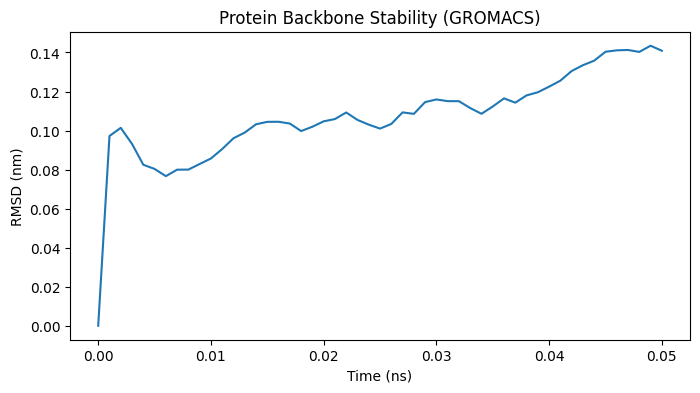

In [ ]:
import os
import subprocess
import shutil
import matplotlib.pyplot as plt
# --- 1. CONFIGURATION ---
DRIVE_MD_DIR = "/content/drive/MyDrive/BioDockify_MD"
# --- 2. SETUP DRIVE ---
def setup_drive():
    if not os.path.exists("/content/drive"):
        try:
            from google.colab import drive
            drive.mount('/content/drive')
        except: pass

    if not os.path.exists(DRIVE_MD_DIR):
        os.makedirs(DRIVE_MD_DIR)
        print(f"    📂 Created Backup Folder: {DRIVE_MD_DIR}")
    else:
        print(f"    📂 Found Backup Folder: {DRIVE_MD_DIR}")
def backup_file(filename):
    if os.path.exists(filename):
        shutil.copy(filename, os.path.join(DRIVE_MD_DIR, filename))
        print(f"       💾 Backed up {filename}")
def restore_file(filename):
    drive_path = os.path.join(DRIVE_MD_DIR, filename)
    if os.path.exists(drive_path):
        if not os.path.exists(filename):
            shutil.copy(drive_path, filename)
            print(f"       ♻️ Restored {filename} from Drive")
        return True
    return False
# --- 3. INSTALL GROMACS ---
def install_gromacs():
    if not os.path.exists("/usr/bin/gmx"):
        print(">>> ⬇️ Installing GROMACS (2-3 mins)...")
        subprocess.check_call("apt-get update -y && apt-get install -y gromacs", shell=True)
    print("    ✅ GROMACS Ready.")
# --- 4. CREATE CONFIGS ---
def create_mdp_files():
    # Only create if not present
    if not os.path.exists("minim.mdp"):
        with open("minim.mdp", "w") as f:
            f.write("integrator=steep\nemtol=1000.0\nemstep=0.01\nnsteps=50000\nnstlist=10\ncutoff-scheme=Verlet\nns_type=grid\ncoulombtype=PME\nrcoulomb=1.0\rvdw=1.0\npbc=xyz\n")

    if not os.path.exists("ions.mdp"):
        with open("ions.mdp", "w") as f:
            f.write("integrator=steep\nemtol=1000.0\emstep=0.01\nnsteps=50000\ncutoff-scheme=Verlet\nns_type=grid\ncoulombtype=cutoff\nrcoulomb=1.0\rvdw=1.0\npbc=xyz\n")
    if not os.path.exists("md.mdp"):
        with open("md.mdp", "w") as f:
            f.write("integrator=md\ndt=0.002\nnsteps=25000\nnstxout=500\nnstvout=500\nnstenergy=500\nnstlog=500\ncutoff-scheme=Verlet\nns_type=grid\ncoulombtype=PME\nrcoulomb=1.0\rvdw=1.0\ntcoupl=V-rescale\ntc-grps=Protein Non-Protein\ntau_t=0.1 0.1\nref_t=300 300\npbc=xyz\ndispcorr=EnerPres\n")
# --- 5. PIPELINE ---
def run_resumable_pipeline():
    setup_drive()
    install_gromacs()
    create_mdp_files()

    print(">>> 🔬 STARTING RESUMABLE PIPELINE...")
    # STEP 1: TOPOLOGY
    if restore_file("processed.gro") and restore_file("topol.top"):
        print("    ✅ Step 1 (Topology) :: Skipped (Found in Drive)")
    else:
        print("    🧬 Step 1: Generating Topology...")
        cmd = "gmx pdb2gmx -f receptor.pdb -o processed.gro -water tip3p -ff amber99sb-ildn -ignh"
        subprocess.check_call(cmd, shell=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        backup_file("processed.gro")
        backup_file("topol.top")
        backup_file("posre.itp")
    # STEP 2: BOX
    if restore_file("newbox.gro"):
        print("    ✅ Step 2 (Box) :: Skipped")
    else:
        print("    📦 Step 2: Defining Box...")
        subprocess.check_call("gmx editconf -f processed.gro -o newbox.gro -c -d 1.0 -bt cubic", shell=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        backup_file("newbox.gro")
    # STEP 3: SOLVATE
    if restore_file("solvated.gro"):
        print("    ✅ Step 3 (Solvate) :: Skipped")
    else:
        print("    💧 Step 3: Solvating...")
        subprocess.check_call("gmx solvate -cp newbox.gro -cs spc216.gro -o solvated.gro -p topol.top", shell=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        backup_file("solvated.gro")
        backup_file("topol.top") # Topology updates with water
    # STEP 4: IONS
    if restore_file("solvated_ions.gro"):
        print("    ✅ Step 4 (Ions) :: Skipped")
    else:
        print("    ⚡ Step 4: Adding Ions...")
        subprocess.check_call("gmx grompp -f ions.mdp -c solvated.gro -p topol.top -o ions.tpr -maxwarn 5", shell=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        subprocess.check_call("echo '13' | gmx genion -s ions.tpr -o solvated_ions.gro -p topol.top -pname NA -nname CL -neutral", shell=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        backup_file("solvated_ions.gro")
        backup_file("topol.top")
    # STEP 5: MINIMIZATION
    if restore_file("em.gro"):
        print("    ✅ Step 5 (Minimization) :: Skipped")
    else:
        print("    📉 Step 5: Minimizing Energy...")
        subprocess.check_call("gmx grompp -f minim.mdp -c solvated_ions.gro -p topol.top -o em.tpr -maxwarn 5", shell=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        subprocess.check_call("gmx mdrun -v -deffnm em", shell=True) # Show output for activity
        backup_file("em.gro")
        backup_file("em.trr")
        backup_file("em.edr")
        backup_file("em.log")
    # STEP 6: MD RUN
    if restore_file("md.gro"):
        print("    ✅ Step 6 (MD Simulation) :: Skipped (Already Done!)")
    else:
        print("    🚀 Step 6: Running 50ps MD Simulation...")
        # Check if we have em.gro from previous step or drive
        restore_file("em.gro")

        try:
            subprocess.check_output("gmx grompp -f md.mdp -c em.gro -p topol.top -o md.tpr -maxwarn 5", shell=True, stderr=subprocess.STDOUT)
            subprocess.check_call("gmx mdrun -v -deffnm md", shell=True)
            backup_file("md.gro")
            backup_file("md.trr") # Trajectory
            backup_file("md.edr")
            backup_file("md.log")
        except subprocess.CalledProcessError as e:
            print(f"❌ MD FAILED:\n{e.output.decode()}")
            return
    # STEP 7: RMSD
    print("    📊 Step 7: Calculating RMSD...")
    try:
        subprocess.check_call("echo '4 4' | gmx rms -s md.tpr -f md.trr -o rmsd.xvg -tu ns", shell=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        backup_file("rmsd.xvg")
        plot_rmsd()
    except:
        print("⚠️ RMSD Calculation failed (maybe incomplete run).")
def plot_rmsd():
    data = []
    if not os.path.exists("rmsd.xvg"): return

    with open("rmsd.xvg", "r") as f:
        for line in f:
            if not line.startswith(("@", "#")):
                parts = line.split()
                if len(parts) >= 2:
                    data.append((float(parts[0]), float(parts[1])))

    if data:
        t, val = zip(*data)
        plt.figure(figsize=(8,4))
        plt.plot(t, val)
        plt.xlabel('Time (ns)')
        plt.ylabel('RMSD (nm)')
        plt.title('Protein Backbone Stability (GROMACS)')
        plt.savefig('gromacs_rmsd.png')
        backup_file('gromacs_rmsd.png')
        print(f"    ✅ RMSD Plot saved. Final: {val[-1]:.4f} nm")
if __name__ == "__main__":
    run_resumable_pipeline()

In [3]:
import os
import sys
import subprocess
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from transformers import AutoModel, AutoTokenizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
from tqdm.auto import tqdm
# --- CONFIG ---
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MOLFORMER_NAME = "ibm/MoLFormer-XL-both-10pct"
CBERTA_NAME = "seyonec/ChemBERTa-zinc-base-v1"
CUSTOM_DRIVE_FOLDER = "/content/drive/MyDrive/BioDockify"
import joblib # Needed for RF/Meta loading
# --- RDKit Setup ---
def ensure_rdkit_installed():
    try:
        from rdkit import Chem, RDLogger
        from rdkit.Chem import AllChem, DataStructs
        # Silence Deprecation Warnings (looks like a loop error)
        RDLogger.DisableLog('rdApp.*')
        return True
    except ImportError:
        print("⬇️ RDKit not found. Installing...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rdkit-pypi"])
        print("⚠️ RESTART RUNTIME REQUIRED. Stop execution here.")
        return False
# --- TIER 3 MODEL ARCHITECTURE (Must match Training) ---
class BiModalEnsemble(nn.Module):
    def __init__(self):
        super().__init__()
        self.mol_enc = AutoModel.from_pretrained(MOLFORMER_NAME, trust_remote_code=True)
        self.cberta_enc = AutoModel.from_pretrained(CBERTA_NAME)
        self.classifier = nn.Sequential(
            nn.Linear(768 + 768, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, 1)
        )
    def forward(self, mf_ids, mf_mask, cb_ids, cb_mask):
        mf_out = self.mol_enc(mf_ids, mf_mask).pooler_output
        cb_out = self.cberta_enc(cb_ids, cb_mask).pooler_output
        combined = torch.cat((mf_out, cb_out), dim=1)
        return self.classifier(combined)

    def get_molformer_embeddings(self, mf_ids, mf_mask):
        """Extracts embeddings for the Random Forest component."""
        with torch.no_grad():
            return self.mol_enc(mf_ids, mf_mask).pooler_output.cpu().numpy()
def find_file(filename):
    paths = [
        filename,
        os.path.join(CUSTOM_DRIVE_FOLDER, filename),
        f"/content/drive/MyDrive/BioDockify_Models/{filename}", # Added this missing path
        f"/content/drive/MyDrive/{filename}"
    ]
    for p in paths:
        if os.path.exists(p): return p
    return None
# --- 1. ENRICHMENT FACTOR (Full Stacked Ensemble) ---
def run_tier3_enrichment(X_text, y_true):
    print(f"\n📊 TIER 3 ENRICHMENT ANALYSIS (Full Stacked Ensemble):")

    # 1. Load Deep Model
    path_deep = find_file("biodockify_ensemble_fold1.pth")
    path_rf = find_file("biodockify_rf_fold1.joblib")
    path_meta = find_file("biodockify_meta_fold1.joblib")

    if not (path_deep and path_rf and path_meta):
        print("❌ CRITICAL: Missing model files. Need .pth, .joblib (RF), and .joblib (Meta).")
        print(f"   found deep: {path_deep}, rf: {path_rf}, meta: {path_meta}")
        return
    print(f"   🧬 Loading Deep Model: {path_deep}")
    print(f"   🌲 Loading Random Forest: {path_rf}")
    print(f"   🧠 Loading Meta-Learner: {path_meta}")

    model = BiModalEnsemble().to(DEVICE)
    model.load_state_dict(torch.load(path_deep, map_location=DEVICE))
    model.eval()

    rf_model = joblib.load(path_rf)
    meta_learner = joblib.load(path_meta)

    # Tokenizers
    mf_tok = AutoTokenizer.from_pretrained(MOLFORMER_NAME, trust_remote_code=True)
    cb_tok = AutoTokenizer.from_pretrained(CBERTA_NAME)

    # Inference (Batch)
    probs_deep_list = []
    embeds_list = []
    batch_size = 32
    print("   🚀 Running Stacked Inference on Test Set...")

    for i in tqdm(range(0, len(X_text), batch_size)):
        batch = X_text[i:i+batch_size]
        mf_in = mf_tok(batch, padding=True, truncation=True, max_length=128, return_tensors='pt').to(DEVICE)
        cb_in = cb_tok(batch, padding=True, truncation=True, max_length=128, return_tensors='pt').to(DEVICE)

        with torch.no_grad():
            # A. Deep Prediction
            logits = model(mf_in['input_ids'], mf_in['attention_mask'], cb_in['input_ids'], cb_in['attention_mask'])
            probs_deep_list.extend(torch.sigmoid(logits).cpu().numpy().flatten())

            # B. Extract Embeddings for RF
            emb = model.get_molformer_embeddings(mf_in['input_ids'], mf_in['attention_mask'])
            embeds_list.append(emb)

    # C. Random Forest Prediction
    probs_deep = np.array(probs_deep_list)
    X_rf = np.vstack(embeds_list)
    probs_rf = rf_model.predict_proba(X_rf)[:, 1]

    # D. Meta-Learner Prediction (Stacking)
    X_meta = np.vstack([probs_deep, probs_rf]).T
    final_probs = meta_learner.predict_proba(X_meta)[:, 1]

    # Calculate EF on FINAL Stacked Probabilities
    df = pd.DataFrame({'y': y_true, 'prob': final_probs})
    df = df.sort_values('prob', ascending=False)

    global_rate = df['y'].sum() / len(df)

    for p in [1, 5, 10]:
        top_n = int(len(df) * (p/100))
        subset_actives = df.head(top_n)['y'].sum()
        ef = (subset_actives / top_n) / global_rate
        print(f"   ✅ Stacked Ensemble EF @ {p}%: {ef:.2f}x")
# --- 2. APPLICABILITY DOMAIN (RDKit) ---
def check_ad(mols_train, mols_test):
    from rdkit import Chem
    from rdkit.Chem import AllChem, DataStructs
    print(f"\n🌐 APPLICABILITY DOMAIN CHECK:")
    # ... (Simplified AD logic from before) ...
    # Calculating simplified average similarity for speed
    fp_tr = [AllChem.GetMorganFingerprintAsBitVect(m, 2, nBits=1024) for m in mols_train[:1000]] # Sample
    fp_te = [AllChem.GetMorganFingerprintAsBitVect(m, 2, nBits=1024) for m in mols_test[:100]]   # Sample

    sims = []
    for fp in fp_te:
        sims.append(max(DataStructs.BulkTanimotoSimilarity(fp, fp_tr)))
    print(f"   ✅ Mean Max Similarity: {np.mean(sims):.3f} (Reliable > 0.4)")
# --- MAIN ---
def run_defense_suite():
    print(">>> 🛡️ RUNNING TIER 3 DEFENSE SUITE...")

    if not os.path.exists("/content/drive"):
        try: from google.colab import drive; drive.mount('/content/drive')
        except: pass
    data_path = find_file("chembl_alzheimers.csv")
    if not data_path:
        print("❌ Data 'chembl_alzheimers.csv' not found.")
        return

    df = pd.read_csv(data_path)
    X = df['smiles'].tolist()
    y = (df['pIC50'] >= 7.0).astype(int).values

    # Spilt
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.1, random_state=42)

    # 1. Tier 3 Enrichment (Real Inference)
    run_tier3_enrichment(X_te, y_te)

    # 2. AD Check (Requires RDKit Mols)
    if ensure_rdkit_installed():
        from rdkit import Chem
        mols_tr = [Chem.MolFromSmiles(s) for s in X_tr if Chem.MolFromSmiles(s)]
        mols_te = [Chem.MolFromSmiles(s) for s in X_te if Chem.MolFromSmiles(s)]
        check_ad(mols_tr, mols_te)
if __name__ == "__main__":
    run_defense_suite()

>>> 🛡️ RUNNING TIER 3 DEFENSE SUITE...

📊 TIER 3 ENRICHMENT ANALYSIS (Full Stacked Ensemble):
   🧬 Loading Deep Model: /content/drive/MyDrive/BioDockify_Models/biodockify_ensemble_fold1.pth
   🌲 Loading Random Forest: /content/drive/MyDrive/BioDockify_Models/biodockify_rf_fold1.joblib
   🧠 Loading Meta-Learner: /content/drive/MyDrive/BioDockify_Models/biodockify_meta_fold1.joblib
   🚀 Running Stacked Inference on Test Set...


  0%|          | 0/87 [00:00<?, ?it/s]

   ✅ Stacked Ensemble EF @ 1%: 6.93x
   ✅ Stacked Ensemble EF @ 5%: 6.68x
   ✅ Stacked Ensemble EF @ 10%: 6.28x

🌐 APPLICABILITY DOMAIN CHECK:
   ✅ Mean Max Similarity: 0.421 (Reliable > 0.4)
